# Developmental Project - Main
- Computation of S-A axis and features of S-A axis development
-  Plotting (Figures 1 & 2)
-  FC strength computation

## Load Packages

In [1]:
# General
import os
import sys
import numpy as np
import pandas as pd
import csv
import math
from math import isnan
import statistics
import pickle
from collections import Counter

# Computing / Analyses
import scipy.io  # loadmat
import hdf5storage  # hdf5storage to write in HDF5 format (instead of .mat file, when matrix is too large) -> hdf5storage.write() hdf5storage.read()
import fnmatch # for comparing patterns of syntax
from scipy import stats
import sklearn 
from brainstat.stats.terms import FixedEffect
from brainstat.stats.SLM import SLM
from statsmodels.stats.multitest import fdrcorrection # does not yield exactly the same FDR correction as R but the same up to 14th decimal place so good enough
import statsmodels.regression.mixed_linear_model as sm
from sklearn.preprocessing import scale

# Visualisation
import matplotlib.pyplot as plt 
import seaborn as sns
import vtk
from IPython.display import display
import matplotlib.collections as clt
import matplotlib.colors as mcolors
#import ptitprince as pt  # commented out because clashing dependencies with seaborn

# Neuroimaging
import nibabel as nib
import nilearn
from brainstat.datasets import fetch_parcellation
from enigmatoolbox.permutation_testing import spin_test, shuf_test

# Gradients
import brainspace
from brainspace.datasets import load_parcellation, load_conte69
from brainspace.plotting import plot_hemispheres
from brainspace.gradient import GradientMaps
from brainspace.utils.parcellation import map_to_labels

## Define directories

In [67]:
codedir = os.path.abspath('')  # obtain current direction from which script is runnning

datadir_local = '/data/p_02667/development/data/'
datadir_local_pds_cleaned = '/data/p_02667/development/data/pds_cleaned/'
datadir = '/data/pt_02667/data/ABCD/'

resdir_fig = '/data/p_02667/development/results/supplementary/fig1_agebins/' 

## Import functions

In [3]:
%run p3_myfunctions.ipynb

# Data 

## Import the Yeo 7 network coding for the Schaefer 400 parcellation scheme

In [4]:
# labels: 1=visual, 2=sensory motor, 3=dorsal attention, 4=ventral attention, 5=limbic, 6=fronto parietal, 7= DMN

yeo7_networks_array = np.genfromtxt('/data/pt_02667/data/yeo_7.csv', delimiter=',', skip_header=0)

### Define custom yeo 7 colormap

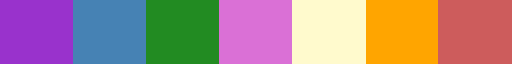

In [5]:
from matplotlib.colors import ListedColormap

# define custom colormap using color names (in order of corresponding networks: 1 visual, 2 sensorimotor, 3 dorsal attention, 4 ventral attention, 5 limbic, 6 fronto parietal, 7 DMN)
colors_yeo7 = ['darkorchid', 'steelblue', 'forestgreen', 'orchid', 'lemonchiffon', 'orange',  'indianred']

yeo7_colormap = ListedColormap(colors_yeo7, 'custom_colormap')

yeo7_colormap

In [6]:
# original Yeo network colors
palette_labeled_networks = {'DMN': 'indianred',  
                            'dorsal attention' : 'forestgreen',  
                            'fronto parietal' : 'orange',  
                            'limbic' : 'lemonchiffon',  
                            'sensory motor' : 'steelblue',
                            'ventral attention' : 'orchid', 
                            'visual' : 'darkorchid'} 

# making an array with yeo network labels (names instead of numbers)
yeo7_networks_array_labels = []

for i in yeo7_networks_array:
    if i == 1:
        yeo7_networks_array_labels.append('visual')
    elif i == 2:
        yeo7_networks_array_labels.append('sensory motor')
    elif i == 3:
        yeo7_networks_array_labels.append('dorsal attention')
    elif i == 4:
        yeo7_networks_array_labels.append('ventral attention')
    elif i == 5:
        yeo7_networks_array_labels.append('limbic')
    elif i == 6:
        yeo7_networks_array_labels.append('fronto parietal')
    elif i == 7:
        yeo7_networks_array_labels.append('DMN')

yeo7_networks_array_labels = np.asarray(yeo7_networks_array_labels)

network_names = ["visual", "sensory motor", "dorsal attention", "ventral attention", "limbic", "fronto parietal", "DMN"]

print("Number of parcels in each Yeo network:")
for i in range(len(network_names)):
    print(f"- {network_names[i]}: {yeo7_networks_array_labels.tolist().count(network_names[i])}")

Number of parcels in each Yeo network:
- visual: 61
- sensory motor: 77
- dorsal attention: 46
- ventral attention: 47
- limbic: 26
- fronto parietal: 53
- DMN: 90


## Fetch fsaverage parcellation (20484 vertices) coded for Schaefer 400 parcels 
**NOTE: schaefer_400_fs5 == 0 corresponds to midline (labels go from 0-400) -> disregard 0 in calculations and plotting**

In [7]:
# fetch the fsaverage parcellation labeling each of fsaverage5's 20484 vertices with its corresponding Schaefer parcel
schaefer_400_fs5 = fetch_parcellation("fsaverage5", "schaefer", 400)

In [8]:
schaefer_400_fs5.shape

(20484,)

## Fetch subject lists

## HCP adult gradients (G1 / S-A axis) + sex effects

### Margulies gradient G1

In [9]:
Margulies_gradients_fsa5 = []
Margulies_gradients_schaefer400 = []

# Margulies published first 5 gradients
for i in range(1,6):

    # load left and right hemispheres (.agg_data() makes the Gifti format accessible) -> shape per hemi is 10242
    Margulies_fsa5_grad_L = nib.load('/data/p_02667/development/data/Gradients_Margulies2016/Gradients_Margulies2016/fsaverage/hcp.embed.grad_'+str(i)+'.L.fsa5.func.gii').agg_data()
    Margulies_fsa5_grad_R = nib.load('/data/p_02667/development/data/Gradients_Margulies2016/Gradients_Margulies2016/fsaverage/hcp.embed.grad_'+str(i)+'.R.fsa5.func.gii').agg_data()


    # concatenate left and right hemispheres - this data is shaped (20484), corresponding to vertices (including medial wall)
    Margulies_fsa5_grad_wholebrain = np.concatenate((Margulies_fsa5_grad_L, Margulies_fsa5_grad_R), axis=0)

    # append to list
    Margulies_gradients_fsa5.append(Margulies_fsa5_grad_wholebrain)

    # transform to Schaefer parcellation and append to list
    Margulies_gradients_schaefer400.append(fs5_to_schaefer400(Margulies_fsa5_grad_wholebrain, seven_networks=True))


Margulies_gradients_fsa5 = np.array(Margulies_gradients_fsa5)
Margulies_gradients_schaefer400 = np.array(Margulies_gradients_schaefer400)

In [10]:
Margulies_gradients_fsa5.shape

(5, 20484)

In [11]:
Margulies_gradients_schaefer400.T.shape

(400, 5)

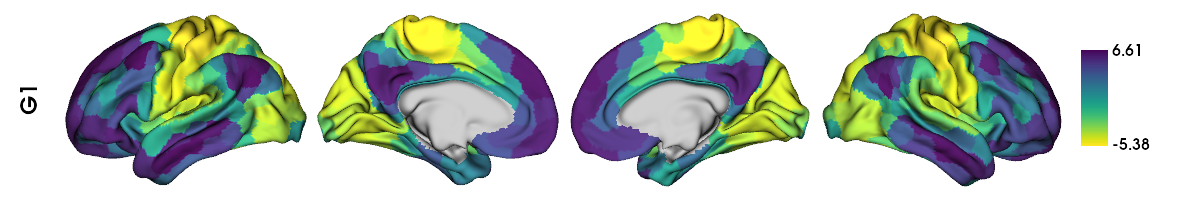

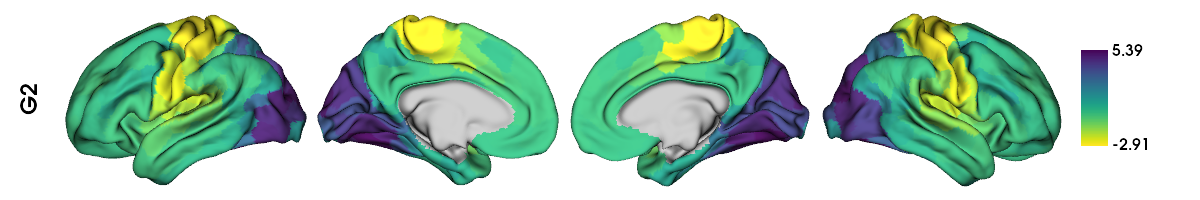

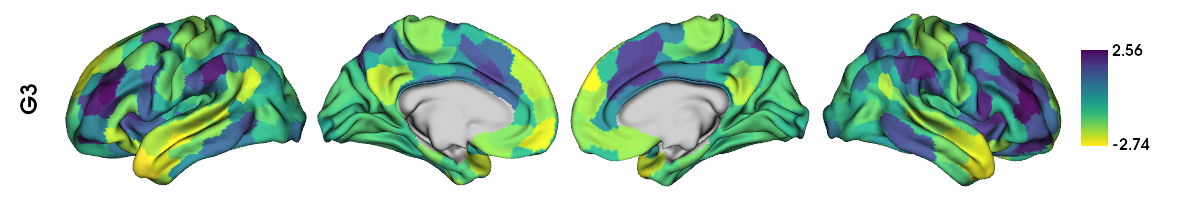

In [68]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

for i in range(3):
    # map the gradient to the parcels
    grad = map_to_labels(Margulies_gradients_schaefer400[i], labeling, mask=mask, fill=np.nan)

    plot = plot_hemispheres(surf_lh, 
                            surf_rh, 
                            array_name=grad, 
                            embed_nb = True, 
                            size=(1200, 200),
                            cmap='viridis_r', 
                            nan_color = (0.7, 0.7, 0.7, 1),
                            color_bar=True, 
                            label_text=[f'G{i+1}'], 
                            zoom=1.55,
                            screenshot = False,
                            #filename = resdir_fig+'_plotted_hemispheres_TO_DEFINE.png'
    )

    display(plot)

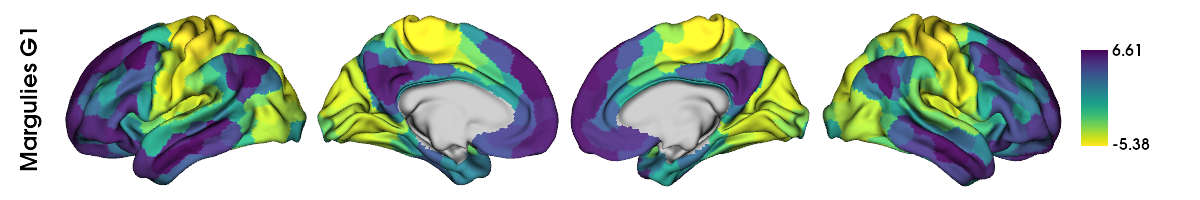

In [69]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(Margulies_gradients_schaefer400[0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        #color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Margulies G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_ref_Margulies_SAaxis.svg')

display(plot)

## Cleaned FC matrices

From p3_cleaning_final_sample.py

### Baseline

In [70]:
## This is current largest sample

# Loading HDF file (file was too large for matfile), with HDF reader e.g., hdf5storage
hdf_file_fc_matrices_baseline_clean = hdf5storage.read(filename=datadir_local+'abcd_fc_matrices_baseline_clean.h5')
hdf_file_fc_matrices_baseline_clean.keys()

dict_keys(['fc_matrices_baseline', 'fc_matrices_baseline_z', 'sub_ID_baseline'])

In [71]:
fc_matrices_baseline = hdf_file_fc_matrices_baseline_clean['fc_matrices_baseline_z']   # take r-to-z transformed matrices
sub_ID_baseline = hdf_file_fc_matrices_baseline_clean['sub_ID_baseline']

fc_matrices_baseline.shape

(4064, 400, 400)

### 2y follow-up

In [72]:
## This is current largest sample

# Loading HDF file (file was too large for matfile), with HDF reader e.g., hdf5storage
hdf_file_fc_matrices_fu2y_clean = hdf5storage.read(filename=datadir_local+'abcd_fc_matrices_fu2y_clean.h5')
hdf_file_fc_matrices_fu2y_clean.keys()

dict_keys(['fc_matrices_fu2y', 'fc_matrices_fu2y_z', 'sub_ID_fu2y'])

In [73]:
fc_matrices_fu2y = hdf_file_fc_matrices_fu2y_clean['fc_matrices_fu2y_z']  # take r-to-z transformed matrices
sub_ID_fu2y = hdf_file_fc_matrices_fu2y_clean['sub_ID_fu2y']

fc_matrices_fu2y.shape

(1296, 400, 400)

### 4y follow-up

In [74]:
## This is current largest sample

# Loading HDF file (file was too large for matfile), with HDF reader e.g., hdf5storage
hdf_file_fc_matrices_fu4y_clean = hdf5storage.read(filename=datadir_local+'abcd_fc_matrices_fu4y_clean.h5')
hdf_file_fc_matrices_fu4y_clean.keys()

dict_keys(['fc_matrices_fu4y', 'fc_matrices_fu4y_z', 'sub_ID_fu4y'])

In [75]:
fc_matrices_fu4y = hdf_file_fc_matrices_fu4y_clean['fc_matrices_fu4y_z']  # take r-to-z transformed matrices
sub_ID_fu4y = hdf_file_fc_matrices_fu4y_clean['sub_ID_fu4y']

fc_matrices_fu4y.shape

(963, 400, 400)

### full (all) -> make it by hand by concatenating the above

In [76]:
fc_matrices_all = np.concatenate((fc_matrices_baseline, fc_matrices_fu2y, fc_matrices_fu4y), axis=0) 
fc_matrices_all.shape

(6323, 400, 400)

In [77]:
sub_ID_all = np.concatenate((sub_ID_baseline, sub_ID_fu2y, sub_ID_fu4y))
sub_ID_all.shape

(6323,)

## Sample

### Baseline

In [78]:
# Load puberty and demographics data
abcd_demo_baseline_clean = pd.read_csv(datadir_local+'abcd_demo_baseline_clean.csv')

In [79]:
# Safety check that sub ID list and demographics subjects are identical (order and elements) - this was done in the cleaning step normally
np.array_equal(np.array(sub_ID_baseline), np.array(abcd_demo_baseline_clean.src_subject_id_fmt))

True

In [80]:
abcd_demo_baseline_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV003RTV85,10.0,F,13.0,baseline_year_1_arm_1,site06,8781.0,131.0,3.0,3.0,1.60,2.4,0.961662,188827.953554,4.0,1.0,1.0,3.0
1,sub-NDARINV007W6H7B,10.0,M,19.0,baseline_year_1_arm_1,site22,4722.0,126.0,2.0,1.0,1.50,1.0,0.550824,233329.288961,23.0,8.0,2.0,0.0
2,sub-NDARINV00J52GPG,9.0,M,21.0,baseline_year_1_arm_1,site17,4151.0,110.0,2.0,2.0,1.40,1.6,1.129072,201853.751338,11.0,0.0,1.0,0.0
3,sub-NDARINV00LH735Y,9.0,M,13.0,baseline_year_1_arm_1,site03,6069.0,109.0,1.0,1.0,1.00,1.4,1.570677,204865.644678,8.0,4.0,2.0,0.0
4,sub-NDARINV00NPMHND,9.0,F,18.0,baseline_year_1_arm_1,site17,4152.0,118.0,2.0,3.0,1.50,1.8,0.363954,212433.396427,42.0,23.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4059,sub-NDARINVZZ6ZJ2KY,10.0,F,18.0,baseline_year_1_arm_1,site06,9345.0,124.0,3.0,3.0,2.00,2.2,1.702236,177613.660710,20.0,0.0,9.0,1.0
4060,sub-NDARINVZZ81LEEV,9.0,M,15.0,baseline_year_1_arm_1,site11,8433.0,108.0,2.0,2.0,1.40,1.6,-1.418958,207555.526432,13.0,2.0,1.0,6.0
4061,sub-NDARINVZZFG6J5U,10.0,F,19.0,baseline_year_1_arm_1,site04,2568.0,129.0,3.0,2.0,2.25,1.6,2.629741,202282.483752,79.0,39.0,12.0,3.0
4062,sub-NDARINVZZNX6W2P,10.0,M,18.0,baseline_year_1_arm_1,site14,3797.0,131.0,1.0,1.0,1.20,1.0,-0.395219,179263.352104,15.0,4.0,7.0,0.0


In [81]:
print(f"{np.sum(abcd_demo_baseline_clean.sex == 'F')} females, {np.sum(abcd_demo_baseline_clean.sex == 'M')} males")

2105 females, 1959 males


### 2y follow-up

In [82]:
# Load puberty and demographics data
abcd_demo_fu2y_clean = pd.read_csv(datadir_local+'abcd_demo_fu2y_clean.csv')

In [83]:
# Safety check that sub ID list and demographics subjects are identical (order and elements) - this was done in the cleaning step normally
np.array_equal(np.array(sub_ID_fu2y), np.array(abcd_demo_fu2y_clean.src_subject_id_fmt))

True

In [84]:
abcd_demo_fu2y_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV00CY2MDM,10.0,M,15.0,2_year_follow_up_y_arm_1,site20,5355.0,152.0,2.0,3.0,1.6,2.2,0.735892,189608.041081,46.0,9.0,25.0,1.0
1,sub-NDARINV00HEV6HB,10.0,M,13.0,2_year_follow_up_y_arm_1,site12,2257.0,149.0,3.0,2.0,2.4,1.8,-0.617092,178850.368164,29.0,5.0,14.0,0.0
2,sub-NDARINV01NAYMZH,10.0,M,18.0,2_year_follow_up_y_arm_1,site16,862.0,153.0,3.0,2.0,2.6,1.8,0.043811,200736.857515,3.0,0.0,1.0,3.0
3,sub-NDARINV01RGTWD2,9.0,F,19.0,2_year_follow_up_y_arm_1,site02,11327.0,135.0,3.0,3.0,1.8,1.6,-0.517889,176978.759778,37.0,13.0,11.0,0.0
4,sub-NDARINV021403LF,9.0,M,19.0,2_year_follow_up_y_arm_1,site05,470.0,131.0,1.0,1.0,1.4,1.6,1.270155,201284.441896,11.0,1.0,3.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1291,sub-NDARINVZUXFF006,9.0,F,21.0,2_year_follow_up_y_arm_1,site12,1851.0,134.0,2.0,2.0,1.6,1.6,0.541296,183254.429205,2.0,0.0,2.0,1.0
1292,sub-NDARINVZWE6CD6Y,10.0,M,16.0,2_year_follow_up_y_arm_1,site13,8301.0,144.0,3.0,2.0,2.2,1.8,-0.045959,190035.640485,31.0,3.0,10.0,6.0
1293,sub-NDARINVZXF5C635,10.0,F,19.0,2_year_follow_up_y_arm_1,site06,9344.0,146.0,3.0,3.0,2.4,2.6,0.253033,195177.892501,33.0,10.0,8.0,1.0
1294,sub-NDARINVZZNX6W2P,10.0,M,18.0,2_year_follow_up_y_arm_1,site14,3797.0,156.0,2.0,1.0,1.4,1.2,-0.304549,177415.148463,13.0,1.0,6.0,2.0


In [85]:
print(f"{np.sum(abcd_demo_fu2y_clean.sex == 'F')} females, {np.sum(abcd_demo_fu2y_clean.sex == 'M')} males")

654 females, 642 males


### 4y follow-up

In [86]:
# Load puberty and demographics data
abcd_demo_fu4y_clean = pd.read_csv(datadir_local+'abcd_demo_fu4y_clean.csv')

In [87]:
# Safety check that sub ID list and demographics subjects are identical (order and elements) - this was done in the cleaning step normally
np.array_equal(np.array(sub_ID_fu4y), np.array(abcd_demo_fu4y_clean.src_subject_id_fmt))

True

In [88]:
abcd_demo_fu4y_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV02EBX0JJ,9.0,M,17.0,4_year_follow_up_y_arm_1,site02,11873.0,168.0,3.0,3.0,2.8,2.80,-0.037103,179791.049460,20.0,5.0,5.0,2.0
1,sub-NDARINV0387TP8R,9.0,M,21.0,4_year_follow_up_y_arm_1,site20,5358.0,160.0,3.0,3.0,2.8,2.80,0.508041,199571.441115,8.0,4.0,2.0,0.0
2,sub-NDARINV07XXFHDK,10.0,M,18.0,4_year_follow_up_y_arm_1,site06,8788.0,171.0,4.0,4.0,3.2,3.60,1.355655,231790.922914,0.0,0.0,0.0,0.0
3,sub-NDARINV08R2PTT1,10.0,M,18.0,4_year_follow_up_y_arm_1,site21,4723.0,181.0,3.0,NaN,2.8,3.25,0.503497,211828.877153,26.0,8.0,7.0,4.0
4,sub-NDARINV09T2EBX4,9.0,F,16.0,4_year_follow_up_y_arm_1,site13,7614.0,159.0,4.0,4.0,3.0,3.00,1.159164,188029.592484,3.0,2.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.0,3.00,-0.503814,206655.702684,0.0,0.0,0.0,0.0
959,sub-NDARINVZYRTFYRP,9.0,M,13.0,4_year_follow_up_y_arm_1,site10,10925.0,164.0,1.0,3.0,1.6,2.60,-0.428811,173346.170313,20.0,4.0,5.0,1.0
960,sub-NDARINVZZ1MNPK5,10.0,F,20.0,4_year_follow_up_y_arm_1,site08,7031.0,175.0,5.0,4.0,3.6,3.60,-0.500384,171459.001848,20.0,13.0,2.0,0.0
961,sub-NDARINVZZ81LEEV,9.0,M,15.0,4_year_follow_up_y_arm_1,site11,8433.0,157.0,2.0,2.0,1.2,1.80,-1.408592,202083.016847,6.0,3.0,0.0,0.0


In [89]:
print(f"{np.sum(abcd_demo_fu4y_clean.sex == 'F')} females, {np.sum(abcd_demo_fu4y_clean.sex == 'M')} males")

461 females, 502 males


### Full sample

In [90]:
# Concatenate dataframes
abcd_demo_all_clean = pd.concat([abcd_demo_baseline_clean, abcd_demo_fu2y_clean, abcd_demo_fu4y_clean], axis=0)
abcd_demo_all_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV003RTV85,10.0,F,13.0,baseline_year_1_arm_1,site06,8781.0,131.0,3.0,3.0,1.6,2.4,0.961662,188827.953554,4.0,1.0,1.0,3.0
1,sub-NDARINV007W6H7B,10.0,M,19.0,baseline_year_1_arm_1,site22,4722.0,126.0,2.0,1.0,1.5,1.0,0.550824,233329.288961,23.0,8.0,2.0,0.0
2,sub-NDARINV00J52GPG,9.0,M,21.0,baseline_year_1_arm_1,site17,4151.0,110.0,2.0,2.0,1.4,1.6,1.129072,201853.751338,11.0,0.0,1.0,0.0
3,sub-NDARINV00LH735Y,9.0,M,13.0,baseline_year_1_arm_1,site03,6069.0,109.0,1.0,1.0,1.0,1.4,1.570677,204865.644678,8.0,4.0,2.0,0.0
4,sub-NDARINV00NPMHND,9.0,F,18.0,baseline_year_1_arm_1,site17,4152.0,118.0,2.0,3.0,1.5,1.8,0.363954,212433.396427,42.0,23.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
958,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.0,3.0,-0.503814,206655.702684,0.0,0.0,0.0,0.0
959,sub-NDARINVZYRTFYRP,9.0,M,13.0,4_year_follow_up_y_arm_1,site10,10925.0,164.0,1.0,3.0,1.6,2.6,-0.428811,173346.170313,20.0,4.0,5.0,1.0
960,sub-NDARINVZZ1MNPK5,10.0,F,20.0,4_year_follow_up_y_arm_1,site08,7031.0,175.0,5.0,4.0,3.6,3.6,-0.500384,171459.001848,20.0,13.0,2.0,0.0
961,sub-NDARINVZZ81LEEV,9.0,M,15.0,4_year_follow_up_y_arm_1,site11,8433.0,157.0,2.0,2.0,1.2,1.8,-1.408592,202083.016847,6.0,3.0,0.0,0.0


In [91]:
print(f"{np.sum(abcd_demo_all_clean.sex == 'F')} females, {np.sum(abcd_demo_all_clean.sex == 'M')} males")

3220 females, 3103 males


#### Identifying subjects with impossible PDS (decreasing with age)

In [92]:
def pds_direction_check(g):
    #g = g.dropna()
    age = g['age_months'].to_numpy()
    pds = g['pds_p_score'].to_numpy()
    
    # Sign of change for every pair of visits (+1 up, -1 down, 0 no change)
    d_age = np.sign(age[:, None] - age[None, :])
    d_pds = np.sign(pds[:, None] - pds[None, :])
    agree = d_age * d_pds        # +1 same direction, -1 opposite, 0 one didn't change
    
    return pd.Series({
        'non_decreasing': (agree >= 0).all(),                   # PDS never goes down as age goes up
        'strictly_increasing': (agree[d_age != 0] > 0).all(),   # PDS always goes up as age goes up
    })

check = (abcd_demo_all_clean
         .groupby('src_subject_id_fmt', sort=False)[['age_months', 'pds_p_score']]
         .apply(pds_direction_check))


impossible_pds_subjects = check.index[~check['non_decreasing']]
print(f"Number of subjects with PDS going the opposite way to age: {len(impossible_pds_subjects)}")
print(f"Number of rows/datapoints to exclude (all belonging to subjects with impossible PDS): {len(abcd_demo_all_clean[abcd_demo_all_clean['src_subject_id_fmt'].isin(impossible_pds_subjects)])}")


Number of subjects with PDS going the opposite way to age: 63
Number of rows/datapoints to exclude (all belonging to subjects with impossible PDS): 152


In [93]:
impossible_pds_subjects

Index(['sub-NDARINV0P3ERKVG', 'sub-NDARINV1CGKKTM5', 'sub-NDARINV1CYTVBWT',
       'sub-NDARINV2BPVXTH3', 'sub-NDARINV2J8WHJ3R', 'sub-NDARINV2V8997BF',
       'sub-NDARINV3UNMBY32', 'sub-NDARINV4C8YJ9BG', 'sub-NDARINV4FBVLRNU',
       'sub-NDARINV4LPXB23R', 'sub-NDARINV52K3HFFN', 'sub-NDARINV61RKCL4Y',
       'sub-NDARINV6JF8WUYT', 'sub-NDARINV7JUL4TDF', 'sub-NDARINV7W4K75L0',
       'sub-NDARINV7YZP2ZNL', 'sub-NDARINV8E3TY3RU', 'sub-NDARINV8Y8A8NU0',
       'sub-NDARINV9Z6E4FXG', 'sub-NDARINV9ZFFC49P', 'sub-NDARINVB5VK9XEN',
       'sub-NDARINVB7CUAZH9', 'sub-NDARINVBR0R4R8M', 'sub-NDARINVBWFE6KU6',
       'sub-NDARINVCKTT8HAT', 'sub-NDARINVCX7YWXVP', 'sub-NDARINVE1MRKJ3N',
       'sub-NDARINVEBFULY5Y', 'sub-NDARINVGALZWY31', 'sub-NDARINVGF5M5HN2',
       'sub-NDARINVH3WNU4JB', 'sub-NDARINVH9ERT7NK', 'sub-NDARINVHXY3TJAT',
       'sub-NDARINVJNDY0DWK', 'sub-NDARINVKJDAZKWA', 'sub-NDARINVL5EAF5N9',
       'sub-NDARINVLBJ8E0XH', 'sub-NDARINVLRNZXLDX', 'sub-NDARINVM5F9LGBU',
       'sub-

In [94]:
# VISUALLY CHECKING TO MAKE SURE THE pds_direction_check() worked properly -> confirmed
for i in range(len(impossible_pds_subjects)):
    bad_rows = abcd_demo_all_clean[
        abcd_demo_all_clean['src_subject_id_fmt']==(impossible_pds_subjects[i])]
    
    print(bad_rows[['src_subject_id_fmt', 'age_months', 'pds_p_score']])
    print('')

      src_subject_id_fmt  age_months  pds_p_score
106  sub-NDARINV0P3ERKVG       108.0          1.4
19   sub-NDARINV0P3ERKVG       154.0          1.0

      src_subject_id_fmt  age_months  pds_p_score
204  sub-NDARINV1CGKKTM5       112.0          1.4
64   sub-NDARINV1CGKKTM5       138.0          1.0
40   sub-NDARINV1CGKKTM5       159.0          2.8

      src_subject_id_fmt  age_months  pds_p_score
206  sub-NDARINV1CYTVBWT       124.0          3.4
65   sub-NDARINV1CYTVBWT       165.0          2.5

      src_subject_id_fmt  age_months  pds_p_score
327  sub-NDARINV2BPVXTH3       124.0          1.4
114  sub-NDARINV2BPVXTH3       148.0          1.2
77   sub-NDARINV2BPVXTH3       170.0          2.6

      src_subject_id_fmt  age_months  pds_p_score
352  sub-NDARINV2J8WHJ3R       108.0          1.4
120  sub-NDARINV2J8WHJ3R       130.0          1.0

      src_subject_id_fmt  age_months  pds_p_score
394  sub-NDARINV2V8997BF       116.0          1.2
132  sub-NDARINV2V8997BF       140.0         

#### Removing subjects with impossible PDS (decreasing with age)

##### From full sample

In [95]:
# Mask for the dataframe
keep_df = ~abcd_demo_all_clean['src_subject_id_fmt'].isin(impossible_pds_subjects).to_numpy()

# Mask for the ID array (which defines the order of fc_matrices_all)
keep_fc = ~np.isin(sub_ID_all, impossible_pds_subjects)

print(f"Number of subjects before removal: {len(sub_ID_all)}")

# Apply
abcd_demo_all_clean = abcd_demo_all_clean[keep_df].reset_index(drop=True)
sub_ID_all = sub_ID_all[keep_fc]
fc_matrices_all = fc_matrices_all[keep_fc]

# Sanity checks
print(f"Number of subjects after removal: {len(sub_ID_all)}")
print(f"Rows removed from df: {(~keep_df).sum()}, from FC array: {(~keep_fc).sum()}")
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_all_clean) == fc_matrices_all.shape[0] == len(sub_ID_all)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_all_clean['src_subject_id_fmt'].to_numpy() == sub_ID_all).all()}")

Number of subjects before removal: 6323
Number of subjects after removal: 6171
Rows removed from df: 152, from FC array: 152
Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


##### From baseline

In [96]:
# Mask for the dataframe
keep_df = ~abcd_demo_baseline_clean['src_subject_id_fmt'].isin(impossible_pds_subjects).to_numpy()

# Mask for the ID array (which defines the order of fc_matrices_baseline)
keep_fc = ~np.isin(sub_ID_baseline, impossible_pds_subjects)

print(f"Number of subjects before removal: {len(sub_ID_baseline)}")

# Apply
abcd_demo_baseline_clean = abcd_demo_baseline_clean[keep_df].reset_index(drop=True)
sub_ID_baseline = sub_ID_baseline[keep_fc]
fc_matrices_baseline = fc_matrices_baseline[keep_fc]

# Sanity checks
print(f"Number of subjects after removal: {len(sub_ID_baseline)}")
print(f"Rows removed from df: {(~keep_df).sum()}, from FC array: {(~keep_fc).sum()}")
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_baseline_clean) == fc_matrices_baseline.shape[0] == len(sub_ID_baseline)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_baseline_clean['src_subject_id_fmt'].to_numpy() == sub_ID_baseline).all()}")

Number of subjects before removal: 4064
Number of subjects after removal: 4007
Rows removed from df: 57, from FC array: 57
Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


##### From fu2y

In [97]:
# Mask for the dataframe
keep_df = ~abcd_demo_fu2y_clean['src_subject_id_fmt'].isin(impossible_pds_subjects).to_numpy()

# Mask for the ID array (which defines the order of fc_matrices_fu2y)
keep_fc = ~np.isin(sub_ID_fu2y, impossible_pds_subjects)

print(f"Number of subjects before removal: {len(sub_ID_fu2y)}")

# Apply
abcd_demo_fu2y_clean = abcd_demo_fu2y_clean[keep_df].reset_index(drop=True)
sub_ID_fu2y = sub_ID_fu2y[keep_fc]
fc_matrices_fu2y = fc_matrices_fu2y[keep_fc]

# Sanity checks
print(f"Number of subjects after removal: {len(sub_ID_fu2y)}")
print(f"Rows removed from df: {(~keep_df).sum()}, from FC array: {(~keep_fc).sum()}")
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_fu2y_clean) == fc_matrices_fu2y.shape[0] == len(sub_ID_fu2y)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_fu2y_clean['src_subject_id_fmt'].to_numpy() == sub_ID_fu2y).all()}")

Number of subjects before removal: 1296
Number of subjects after removal: 1235
Rows removed from df: 61, from FC array: 61
Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


##### From fu4y

In [98]:
# Mask for the dataframe
keep_df = ~abcd_demo_fu4y_clean['src_subject_id_fmt'].isin(impossible_pds_subjects).to_numpy()

# Mask for the ID array (which defines the order of fc_matrices_fu4y)
keep_fc = ~np.isin(sub_ID_fu4y, impossible_pds_subjects)

print(f"Number of subjects before removal: {len(sub_ID_fu4y)}")

# Apply
abcd_demo_fu4y_clean = abcd_demo_fu4y_clean[keep_df].reset_index(drop=True)
sub_ID_fu4y = sub_ID_fu4y[keep_fc]
fc_matrices_fu4y = fc_matrices_fu4y[keep_fc]

# Sanity checks
print(f"Number of subjects after removal: {len(sub_ID_fu4y)}")
print(f"Rows removed from df: {(~keep_df).sum()}, from FC array: {(~keep_fc).sum()}")
print(f"Lengths of demographics df and FC matrices array and subjects array match: {len(abcd_demo_fu4y_clean) == fc_matrices_fu4y.shape[0] == len(sub_ID_fu4y)}")
print(f"Demographics df subjects and FC subjects match: {(abcd_demo_fu4y_clean['src_subject_id_fmt'].to_numpy() == sub_ID_fu4y).all()}")

Number of subjects before removal: 963
Number of subjects after removal: 929
Rows removed from df: 34, from FC array: 34
Lengths of demographics df and FC matrices array and subjects array match: True
Demographics df subjects and FC subjects match: True


#
#
# Demographics & Puberty -> by age range for supplements

In [99]:
abcd_demo_all_clean

,src_subject_id_fmt,age_baseline_yrs,sex,edu_parent,eventname,site_id,family_id,age_months,pds_y_cat,pds_p_cat,pds_y_score,pds_p_score,BMIz,tot_SA,cbcl_tot,cbcl_int,cbcl_ext,fam_conflict_y
0,sub-NDARINV003RTV85,10.0,F,13.0,baseline_year_1_arm_1,site06,8781.0,131.0,3.0,3.0,1.6,2.4,0.961662,188827.953554,4.0,1.0,1.0,3.0
1,sub-NDARINV007W6H7B,10.0,M,19.0,baseline_year_1_arm_1,site22,4722.0,126.0,2.0,1.0,1.5,1.0,0.550824,233329.288961,23.0,8.0,2.0,0.0
2,sub-NDARINV00J52GPG,9.0,M,21.0,baseline_year_1_arm_1,site17,4151.0,110.0,2.0,2.0,1.4,1.6,1.129072,201853.751338,11.0,0.0,1.0,0.0
3,sub-NDARINV00LH735Y,9.0,M,13.0,baseline_year_1_arm_1,site03,6069.0,109.0,1.0,1.0,1.0,1.4,1.570677,204865.644678,8.0,4.0,2.0,0.0
4,sub-NDARINV00NPMHND,9.0,F,18.0,baseline_year_1_arm_1,site17,4152.0,118.0,2.0,3.0,1.5,1.8,0.363954,212433.396427,42.0,23.0,3.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6166,sub-NDARINVZYC44GB8,10.0,M,21.0,4_year_follow_up_y_arm_1,site16,1840.0,179.0,4.0,4.0,3.0,3.0,-0.503814,206655.702684,0.0,0.0,0.0,0.0
6167,sub-NDARINVZYRTFYRP,9.0,M,13.0,4_year_follow_up_y_arm_1,site10,10925.0,164.0,1.0,3.0,1.6,2.6,-0.428811,173346.170313,20.0,4.0,5.0,1.0
6168,sub-NDARINVZZ1MNPK5,10.0,F,20.0,4_year_follow_up_y_arm_1,site08,7031.0,175.0,5.0,4.0,3.6,3.6,-0.500384,171459.001848,20.0,13.0,2.0,0.0
6169,sub-NDARINVZZ81LEEV,9.0,M,15.0,4_year_follow_up_y_arm_1,site11,8433.0,157.0,2.0,2.0,1.2,1.8,-1.408592,202083.016847,6.0,3.0,0.0,0.0


In [100]:
print(f"{np.sum(abcd_demo_all_clean.sex == 'F')} females, {np.sum(abcd_demo_all_clean.sex == 'M')} males")

3168 females, 3003 males


In [101]:
len(pd.unique(abcd_demo_all_clean['src_subject_id_fmt']))

4856

In [102]:
len(pd.unique(abcd_demo_all_clean['family_id']))

4353

## Identfying three bins from full

### Equally sized age bins -> disbalanced age ranges (much larger in age bin 3) -> DON'T USE!

In [189]:
df = abcd_demo_all_clean.copy()

# Split into tertiles (33rd / 67th percentile cut points)
df["age_bin"], bin_edges = pd.qcut(df["age_months"], q=3,
                                   labels=[1, 2, 3], retbins=True)
print("Bin edges (months):", bin_edges)

# Create the three subsets
abcd_demo_age1_clean = df[df["age_bin"] == 1].copy()
abcd_demo_age2_clean = df[df["age_bin"] == 2].copy()
abcd_demo_age3_clean = df[df["age_bin"] == 3].copy()

# Check the balance
print(df.groupby("age_bin", observed=True)["age_months"]
        .agg(["count", "min", "max", "mean"]))

print()
print("in Years")
print((df.assign(age_years=df["age_months"] / 12)
         .groupby("age_bin", observed=True)["age_years"]
         .agg(["count", "min", "max", "mean"])
         .round(2)))

Bin edges (months): [107. 120. 132. 187.]
         count    min    max        mean
age_bin                                 
1         2083  107.0  120.0  113.410946
2         2046  121.0  132.0  126.817693
3         2042  133.0  187.0  155.985798

in Years
         count    min    max   mean
age_bin                            
1         2083   8.92  10.00   9.45
2         2046  10.08  11.00  10.57
3         2042  11.08  15.58  13.00


#### Checking whether there are duplicate subjects in the same age bin (for info - not excluding them to keep sample)

In [190]:
subsets = {
    "age1": abcd_demo_age1_clean,
    "age2": abcd_demo_age2_clean,
    "age3": abcd_demo_age3_clean,
}

for name, d in subsets.items():
    n_rows = len(d)
    n_unique = d["src_subject_id_fmt"].nunique()
    n_dup = d["src_subject_id_fmt"].duplicated().sum()
    print(f"{name}: {n_rows} rows, {n_unique} unique subjects, {n_dup} duplicate rows")

age1: 2083 rows, 2083 unique subjects, 0 duplicate rows
age2: 2046 rows, 2046 unique subjects, 0 duplicate rows
age3: 2042 rows, 1593 unique subjects, 449 duplicate rows


In [191]:
dups = abcd_demo_age3_clean[abcd_demo_age3_clean["src_subject_id_fmt"].duplicated(keep=False)]
print(dups.sort_values("src_subject_id_fmt")[["src_subject_id_fmt", "eventname", "age_months"]])

       src_subject_id_fmt                 eventname  age_months
4012  sub-NDARINV02EBX0JJ  2_year_follow_up_y_arm_1       141.0
5242  sub-NDARINV02EBX0JJ  4_year_follow_up_y_arm_1       168.0
4021  sub-NDARINV08R2PTT1  2_year_follow_up_y_arm_1       153.0
5245  sub-NDARINV08R2PTT1  4_year_follow_up_y_arm_1       181.0
4023  sub-NDARINV0B7UGM1D  2_year_follow_up_y_arm_1       137.0
...                   ...                       ...         ...
5231  sub-NDARINVZJYGP0WE  2_year_follow_up_y_arm_1       155.0
6163  sub-NDARINVZT1J0KUC  4_year_follow_up_y_arm_1       168.0
5235  sub-NDARINVZT1J0KUC  2_year_follow_up_y_arm_1       143.0
5239  sub-NDARINVZXF5C635  2_year_follow_up_y_arm_1       146.0
6165  sub-NDARINVZXF5C635  4_year_follow_up_y_arm_1       172.0

[898 rows x 3 columns]


In [192]:
# check number of subjects appearing in more than 1 subset

ids1 = set(abcd_demo_age1_clean["src_subject_id_fmt"])
ids2 = set(abcd_demo_age2_clean["src_subject_id_fmt"])
ids3 = set(abcd_demo_age3_clean["src_subject_id_fmt"])

print("In bins 1 & 2:", len(ids1 & ids2))
print("In bins 1 & 3:", len(ids1 & ids3))
print("In bins 2 & 3:", len(ids2 & ids3))

In bins 1 & 2: 72
In bins 1 & 3: 356
In bins 2 & 3: 466


#### Plot Age

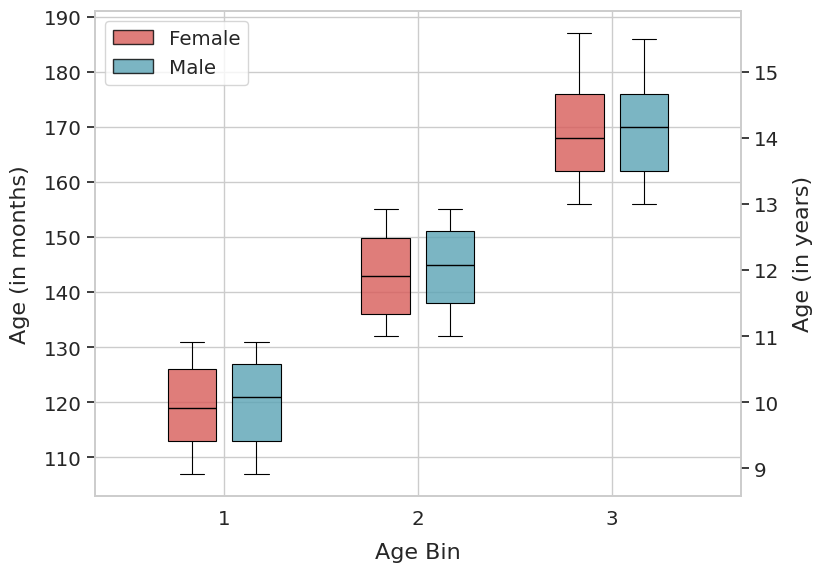

In [199]:
from matplotlib.patches import Patch
import matplotlib.colors as mcolors

bins = ["1", "2", "3"]

alpha_map = {
    "1": 0.8,  # 0.8
    "2": 0.8,  # 0.6
    "3": 0.8  # 0.3
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_age1_clean,
    abcd_demo_age2_clean,
    abcd_demo_age3_clean
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8.5, 6))

# --- Function to draw SEX-SPLIT boxplots with BIN alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(bins):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["age_months"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)


# --- Axis labels and primary formatting ---
ax.set_xticks(np.arange(len(bins)))
ax.set_xticklabels(bins)
ax.set_xlabel("Age Bin", fontsize=16, labelpad=10)
ax.set_ylabel("Age (in months)", fontsize=16, labelpad=10)

# --- Create the second y-axis (Age in years) ---
ax2 = ax.twinx()  # Create a twin axis sharing the x-axis

# Synchronize the limits: 
# We get the current month limits and convert them to years for the second axis
y_min, y_max = ax.get_ylim()
ax2.set_ylim(y_min / 12, y_max / 12)

ax2.set_ylabel("Age (in years)", fontsize=16, labelpad=10)
ax2.grid(False) # Usually cleaner to turn off the second grid

# --- Legend and final touches ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper left", frameon=True)

plt.tight_layout()


#plt.show()

#plt.savefig(resdir_fig + "boxplot_age_by_sex_by_age_bin.svg", format="svg", bbox_inches="tight", dpi=300)


### 

### Manually defined ae bins (meaningful cutoffs while trying to keep a relatively good sample size in each)
### Bin 1: < 11 y | Bin 2: 11 to <13 y | Bin 3: ≥ 13 y 

In [236]:
# sanity check same subject order
print(np.array_equal(abcd_demo_all_clean.src_subject_id_fmt, sub_ID_all))


# Bin on the original dataframe (no dropna, no sorting)
# Bin 1: < 11 y (< 132 mo) | Bin 2: 11 to <13 y (132–155 mo) | Bin 3: ≥ 13 y (≥ 156 mo)
age_bin = pd.cut(abcd_demo_all_clean["age_months"],
                 bins=[-np.inf, 132, 156, np.inf],
                 labels=[1, 2, 3], right=False)


# Boolean masks aligned to row position
mask1 = (age_bin == 1).to_numpy()
mask2 = (age_bin == 2).to_numpy()
mask3 = (age_bin == 3).to_numpy()

# Subset both the dataframe and the FC arrays with the same masks
abcd_demo_age1_clean = abcd_demo_all_clean[mask1].copy()
abcd_demo_age2_clean = abcd_demo_all_clean[mask2].copy()
abcd_demo_age3_clean = abcd_demo_all_clean[mask3].copy()

fc_matrices_age1 = fc_matrices_all[mask1]
fc_matrices_age2 = fc_matrices_all[mask2]
fc_matrices_age3 = fc_matrices_all[mask3]

# Check that sizes match
for k, (d, fc) in enumerate([(abcd_demo_age1_clean, fc_matrices_age1),
                             (abcd_demo_age2_clean, fc_matrices_age2),
                             (abcd_demo_age3_clean, fc_matrices_age3)], start=1):
    print(f"bin {k}: df {len(d)} rows, fc {fc.shape}")

print()

# Check the balance
print(abcd_demo_all_clean.groupby(age_bin, observed=True)["age_months"]
        .agg(["count", "min", "max", "mean"]))

print()
print("in Years")
print((abcd_demo_all_clean["age_months"] / 12)
        .groupby(age_bin, observed=True)
        .agg(["count", "min", "max", "mean"])
        .round(2))

True
bin 1: df 4023 rows, fc (4023, 400, 400)
bin 2: df 1197 rows, fc (1197, 400, 400)
bin 3: df 951 rows, fc (951, 400, 400)

            count    min    max        mean
age_months                                 
1            4023  107.0  131.0  119.739498
2            1197  132.0  155.0  143.527987
3             951  156.0  187.0  168.992639

in Years
            count    min    max   mean
age_months                            
1            4023   8.92  10.92   9.98
2            1197  11.00  12.92  11.96
3             951  13.00  15.58  14.08


#### Checking whether there are duplicate subjects in the same age bin (for info - not excluding them to keep sample)

In [201]:
subsets = {
    "age1": abcd_demo_age1_clean,
    "age2": abcd_demo_age2_clean,
    "age3": abcd_demo_age3_clean,
}

for name, d in subsets.items():
    n_rows = len(d)
    n_unique = d["src_subject_id_fmt"].nunique()
    n_dup = d["src_subject_id_fmt"].duplicated().sum()
    print(f"{name}: {n_rows} rows, {n_unique} unique subjects, {n_dup} duplicate rows")

age1: 4023 rows, 3987 unique subjects, 36 duplicate rows
age2: 1197 rows, 1191 unique subjects, 6 duplicate rows
age3: 951 rows, 927 unique subjects, 24 duplicate rows


In [202]:
dups = abcd_demo_age3_clean[abcd_demo_age3_clean["src_subject_id_fmt"].duplicated(keep=False)]
print(dups.sort_values("src_subject_id_fmt")[["src_subject_id_fmt", "eventname", "age_months"]])

       src_subject_id_fmt                 eventname  age_months
4156  sub-NDARINV3GFD7GXB  2_year_follow_up_y_arm_1       156.0
5351  sub-NDARINV3GFD7GXB  4_year_follow_up_y_arm_1       182.0
5401  sub-NDARINV5A6YDAY7  4_year_follow_up_y_arm_1       179.0
4221  sub-NDARINV5A6YDAY7  2_year_follow_up_y_arm_1       159.0
4408  sub-NDARINVA41WLWNU  2_year_follow_up_y_arm_1       157.0
5530  sub-NDARINVA41WLWNU  4_year_follow_up_y_arm_1       185.0
4500  sub-NDARINVCLA2CZ2U  2_year_follow_up_y_arm_1       156.0
5593  sub-NDARINVCLA2CZ2U  4_year_follow_up_y_arm_1       182.0
4530  sub-NDARINVDA6VVDEG  2_year_follow_up_y_arm_1       156.0
5615  sub-NDARINVDA6VVDEG  4_year_follow_up_y_arm_1       181.0
4536  sub-NDARINVDE3J6HBM  2_year_follow_up_y_arm_1       156.0
5621  sub-NDARINVDE3J6HBM  4_year_follow_up_y_arm_1       182.0
4551  sub-NDARINVDZVTE3N0  2_year_follow_up_y_arm_1       156.0
5637  sub-NDARINVDZVTE3N0  4_year_follow_up_y_arm_1       181.0
4568  sub-NDARINVE85HG9YD  2_year_follow

In [203]:
# check number of subjects appearing in more than 1 subset

ids1 = set(abcd_demo_age1_clean["src_subject_id_fmt"])
ids2 = set(abcd_demo_age2_clean["src_subject_id_fmt"])
ids3 = set(abcd_demo_age3_clean["src_subject_id_fmt"])

print("In bins 1 & 2:", len(ids1 & ids2))
print("In bins 1 & 3:", len(ids1 & ids3))
print("In bins 2 & 3:", len(ids2 & ids3))

In bins 1 & 2: 611
In bins 1 & 3: 444
In bins 2 & 3: 448


#### Plot Age

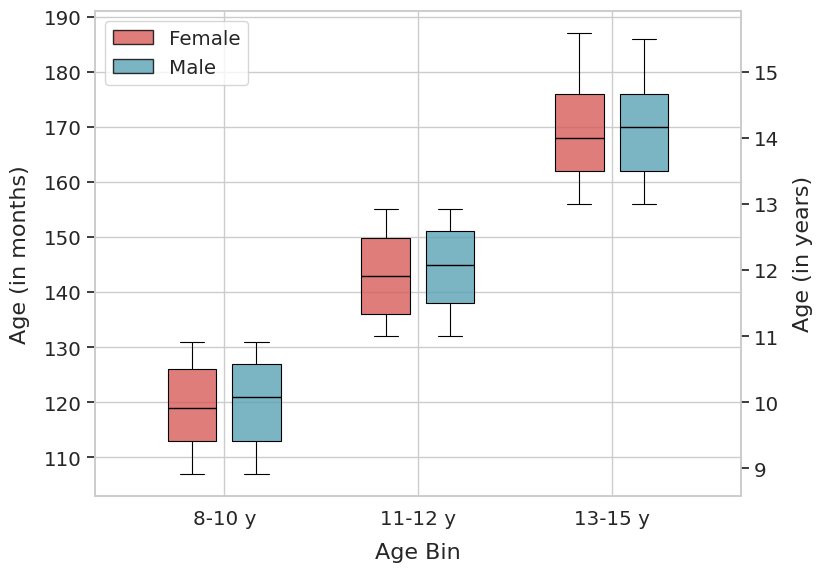

In [204]:
bins = ["8-10 y", "11-12 y", "13-15 y"]

alpha_map = {
    "8-10 y": 0.8,  # 0.8
    "11-12 y": 0.8,  # 0.6
    "13-15 y": 0.8  # 0.3
}

sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_age1_clean,
    abcd_demo_age2_clean,
    abcd_demo_age3_clean
]

# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8.5, 6))

# --- Function to draw SEX-SPLIT boxplots with BIN alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(bins):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["age_months"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)


# --- Axis labels and primary formatting ---
ax.set_xticks(np.arange(len(bins)))
ax.set_xticklabels(bins)
ax.set_xlabel("Age Bin", fontsize=16, labelpad=10)
ax.set_ylabel("Age (in months)", fontsize=16, labelpad=10)

# --- Create the second y-axis (Age in years) ---
ax2 = ax.twinx()  # Create a twin axis sharing the x-axis

# Synchronize the limits: 
# We get the current month limits and convert them to years for the second axis
y_min, y_max = ax.get_ylim()
ax2.set_ylim(y_min / 12, y_max / 12)

ax2.set_ylabel("Age (in years)", fontsize=16, labelpad=10)
ax2.grid(False) # Usually cleaner to turn off the second grid

# --- Legend and final touches ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper left", frameon=True)

plt.tight_layout()

plt.savefig(resdir_fig + "boxplot_age_by_sex_by_age_bin.svg", format="svg", bbox_inches="tight", dpi=300)

#### Puberty

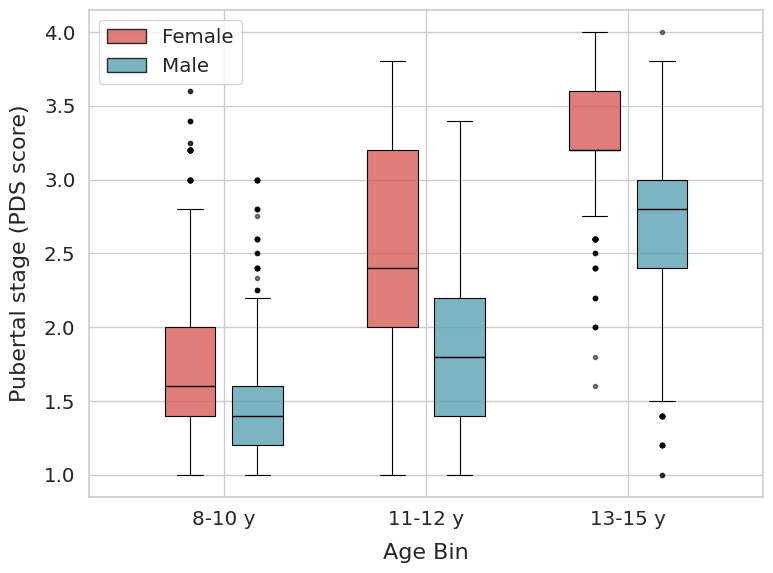

In [206]:
bins = ["8-10 y", "11-12 y", "13-15 y"]

alpha_map = {
    "8-10 y": 0.8,  # 0.8
    "11-12 y": 0.8,  # 0.6
    "13-15 y": 0.8  # 0.3
}


sex_palette = {
    "F": "#d85c59",
    "M": "#5aa3b5"
}

data = [
    abcd_demo_age1_clean,
    abcd_demo_age2_clean,
    abcd_demo_age3_clean
]


# --- Style setup (consistent with your manuscript) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axes ---
fig, ax = plt.subplots(figsize=(8, 6))

# --- Function to draw SEX-SPLIT boxplots with bin alpha ---
def draw_boxplots(ax, data):

    box_width = 0.25
    offsets = [-box_width / 1.5, box_width / 1.5]  # F left, M right

    for tp_idx, tp in enumerate(bins):

        df_tp = data[tp_idx]
        alpha = alpha_map[tp]

        for sex_idx, sex in enumerate(["F", "M"]):

            df_sex = df_tp[df_tp["sex"] == sex]["pds_p_score"].dropna()

            color = sex_palette[sex]
            rgba = mcolors.to_rgba(color, alpha=alpha)

            position = tp_idx + offsets[sex_idx]

            bp = ax.boxplot(
                df_sex,
                positions=[position],
                widths=box_width,
                patch_artist=True,
                boxprops=dict(facecolor=rgba, edgecolor='black', linewidth=0.8),
                medianprops=dict(color='black', linewidth=1),
                whiskerprops=dict(color='black', linewidth=0.8),
                capprops=dict(color='black', linewidth=0.8),
                flierprops=dict(
                    marker='o',
                    markersize=3,
                    alpha=0.5,
                    markerfacecolor='black',
                    markeredgecolor='black'
                )
            )


# --- Draw boxplots ---
draw_boxplots(ax, data)

# --- Axis labels ---
ax.set_xticks(np.arange(len(bins)))
ax.set_xticklabels(bins)
ax.set_xlabel("Age Bin", fontsize=16, labelpad=10)
ax.set_ylabel("Pubertal stage (PDS score)", fontsize=16, labelpad=10)

# --- Legend (Sex only, alpha encoded visually) ---
legend_elements = [
    Patch(facecolor=sex_palette["F"], alpha=0.8, edgecolor="black", label="Female"),
    Patch(facecolor=sex_palette["M"], alpha=0.8, edgecolor="black", label="Male"),
]
ax.legend(handles=legend_elements, loc="upper left", frameon=True)


# Optional: Adjust y-axis limits for tighter framing
# ax.set_ylim(1, 4.5)

plt.tight_layout()
#plt.show()

plt.savefig(resdir_fig + "boxplot_pds_by_sex_by_age_bin.svg", format="svg", bbox_inches="tight", dpi=300)

#
#
#
#
# Compute gradients - Overall - Age Bin 1 (not fc/grad arrays for simplicity)

## Mean gradients

In [115]:
mean_fc_matrix = np.sum(fc_matrices_age1, axis=0)/len(fc_matrices_age1)

In [116]:
mean_fc_matrix.shape

(400, 400)

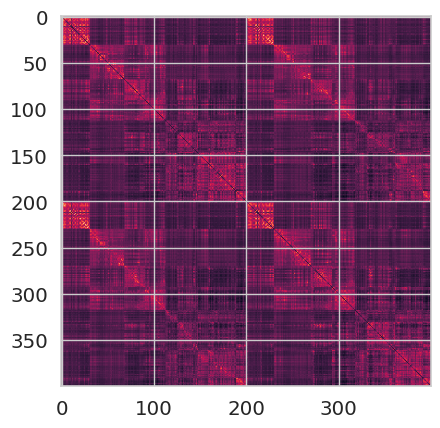

(400, 400)


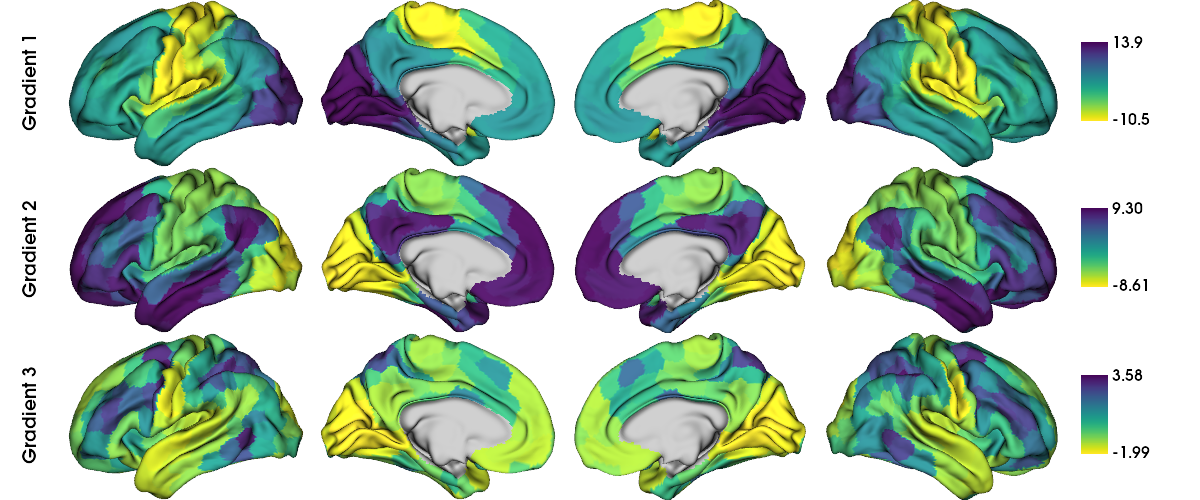

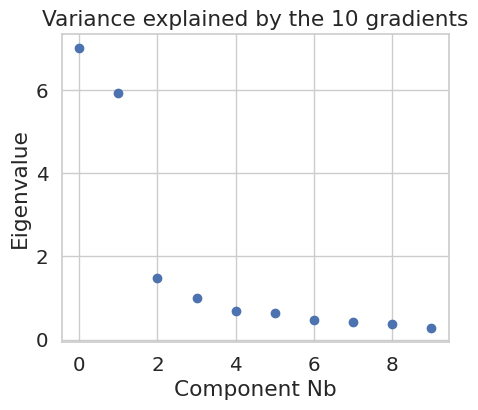

Total amount of variance explained by the 10 gradients (uncorrected sum lambdas): 18.28

G1: 38.32%
G2: 32.40%
G3: 8.06


In [117]:
# don't save these screenshots! (saves G1 and I actually want flipped -> next cells)
mean_fc_grad = compute_mean_gradients(mean_fc_matrix, display_output = True, data_reduction_algorithm = 'dm', kernel='cosine', save_screenshot = False, output_dir = resdir_fig, sample_modality = 'fc')

## Subject-level gradients (NOT ALIGNED)

In [118]:
# compute aligned gradients
compute_indvidual_gradients = compute_indvidual_gradients_NOT_aligned(conn_matrices = fc_matrices_age1, ref_SA_axis = Margulies_gradients_schaefer400[0], data_reduction_algorithm = 'dm', kernel = 'cosine')

# store output of the gradient computation
array_SA_axis_baseline = compute_indvidual_gradients['array_SA_axis']
array_grad_other1_baseline = compute_indvidual_gradients['array_grad_other1']
array_grad_other2_baseline = compute_indvidual_gradients['array_grad_other2']
list_SA_axis_grad_num_baseline = compute_indvidual_gradients['list_SA_axis_grad_num']
list_SA_axis_corr_to_ref_baseline = compute_indvidual_gradients['list_SA_axis_corr_to_ref']
scaled_var_exp_SA_axis_baseline = compute_indvidual_gradients['scaled_var_exp_SA_axis']
scaled_var_exp_other1_baseline = compute_indvidual_gradients['scaled_var_exp_other1']
scaled_var_exp_other2_baseline = compute_indvidual_gradients['scaled_var_exp_other2']
diff_scaled_var_exp_SA_axis_other1_baseline = compute_indvidual_gradients['diff_scaled_var_exp_SA_axis_other1']


/data/u_serio_software/miniforge3/lib/python3.12/site-packages/brainspace/gradient/embedding.py:77: UserWarning: Graph is not fully connected.
  warnings.warn('Graph is not fully connected.')


In [119]:
array_SA_axis_baseline.shape

(4023, 400)

In [120]:
Counter(list_SA_axis_grad_num_baseline)

Counter({1: 2085, 2: 1864, 3: 59, 4: 9, 5: 6})

/tmp/ipykernel_38588/1113933288.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


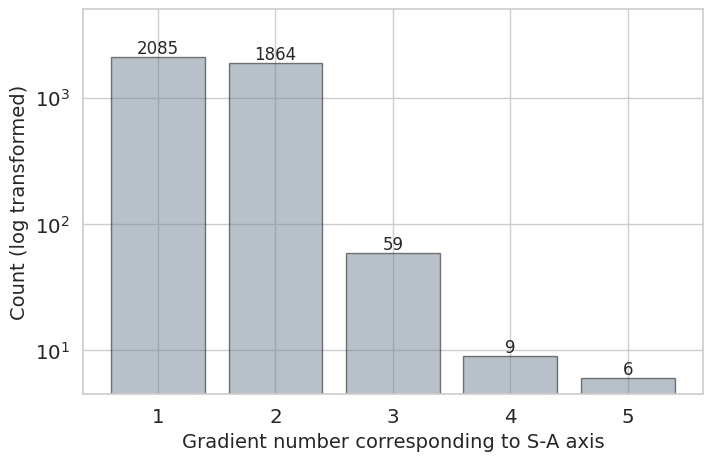

In [121]:
counts = Counter(list_SA_axis_grad_num_baseline)

# Sort by key to keep the x-axis in order
keys = sorted(counts.keys())
values = [counts[k] for k in keys]

# Style setup (match your other figures)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create the bar plot
plt.figure(figsize=(8, 5))

bars = plt.bar(keys, values, color='xkcd:steel', alpha=0.5, edgecolor='black')

plt.xlabel('Gradient number corresponding to S-A axis', fontsize=14)
plt.ylabel('Count (log transformed)', fontsize=14)
#plt.title('Counts of Axis Gradient Numbers at Baseline', fontsize=16)
plt.xticks(keys)
plt.yscale('log')  # log scale
plt.ylim(0, 5000)

# Annotate counts on top of the bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of the bar
        value,                               # y position: top of the bar
        str(value),                          # text to display
        ha='center', va='bottom', fontsize=12
    )

plt.show()


In [122]:
# Compute the loading range for the S-A axis at individual level
SA_axis_baseline_individual_range = np.max(array_SA_axis_baseline, axis=1) - np.min(array_SA_axis_baseline, axis=1) 

In [123]:
print(f"Min correlation: r = {round(np.min(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Max correlation: r = {round(np.max(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Mean correlation: r = {round(np.mean(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Median correlation: r = {round(np.median(list_SA_axis_corr_to_ref_baseline),2)}")
print(f"Mean individual range: r = {round(np.mean(SA_axis_baseline_individual_range),2)}")

Min correlation: r = 0.39
Max correlation: r = 0.94
Mean correlation: r = 0.75
Median correlation: r = 0.75
Mean individual range: r = 14.55


In [124]:
data = list_SA_axis_corr_to_ref_baseline
# Coefficient of variation
print("CV = std / mean. Scale-free measure of relative dispersion")
print(np.std(data, ddof=1) / np.mean(data))

# Interquartile range
print("\nIQR = Q3 - Q1. Middle 50% spread, robust to outliers")
print(np.percentile(data, 75) - np.percentile(data, 25))

# Median absolute deviation
print("\nMAD = median(|xi - median(x)|). Robust, outlier-resistant spread")
print(np.median(np.abs(data - np.median(data))))

# Normalized range
print("\nNR = (max - min) / mean. Simple but sensitive to outliers")
print((np.max(data) - np.min(data)) / np.mean(data))

# Gini coefficient
print("\nGini coefficient. 0 = perfect equality, 1 = maximal inequality")
sorted_data = np.sort(data)
n = len(sorted_data)
index = np.arange(1, n + 1)
print((2 * np.sum(index * sorted_data) / (n * np.sum(sorted_data))) - (n + 1) / n)

CV = std / mean. Scale-free measure of relative dispersion
0.12333475837190352

IQR = Q3 - Q1. Middle 50% spread, robust to outliers
0.13400596253726593

MAD = median(|xi - median(x)|). Robust, outlier-resistant spread
0.06655954099713135

NR = (max - min) / mean. Simple but sensitive to outliers
0.7408668466438223

Gini coefficient. 0 = perfect equality, 1 = maximal inequality
0.07008402415336246


In [125]:
print(f"Min scaled variance explained by S-A axis: {round(np.min(scaled_var_exp_SA_axis_baseline),2)}")
print(f"Max scaled variance explained by S-A axis: {round(np.max(scaled_var_exp_SA_axis_baseline),2)}")
print("")
print(f"Min difference variance explained by S-A axis and other gradient 1: {round(np.min(diff_scaled_var_exp_SA_axis_other1_baseline),2)}")
print(f"Max difference variance explained by S-A axis and other gradient 1: {round(np.max(diff_scaled_var_exp_SA_axis_other1_baseline),2)}")

Min scaled variance explained by S-A axis: 0.86
Max scaled variance explained by S-A axis: 57.58

Min difference variance explained by S-A axis and other gradient 1: -95.31
Max difference variance explained by S-A axis and other gradient 1: 50.8


#
#
#
#
# Compute gradients - Overall - Age Bin 2 (not fc/grad arrays for simplicity)

## Mean gradients

In [126]:
mean_fc_matrix_fu2y = np.sum(fc_matrices_age2, axis=0)/len(fc_matrices_age2)

In [127]:
mean_fc_matrix_fu2y.shape

(400, 400)

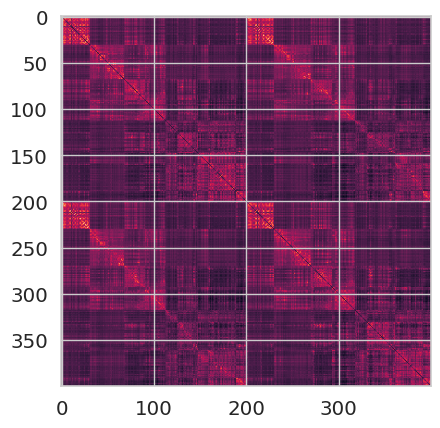

(400, 400)


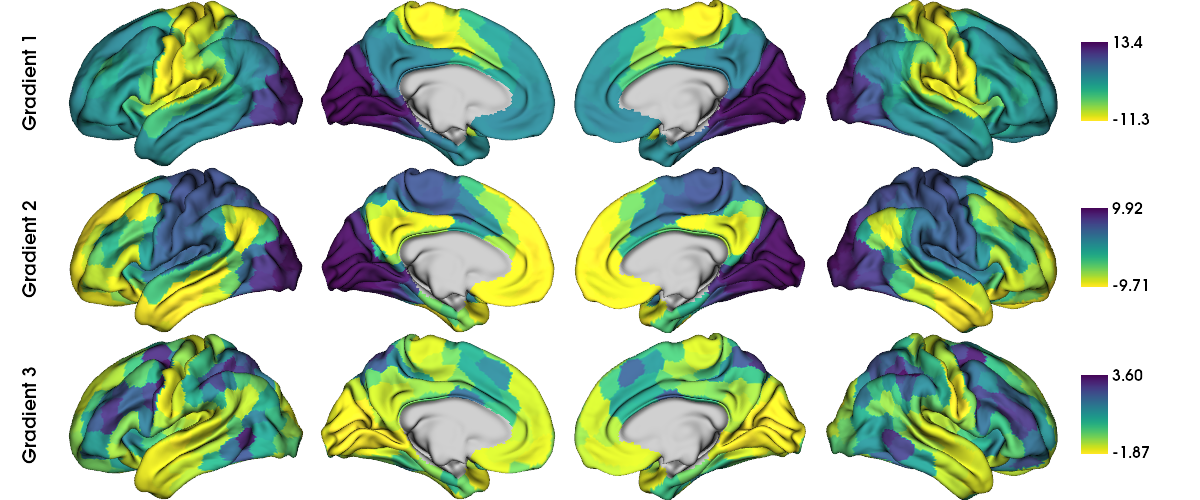

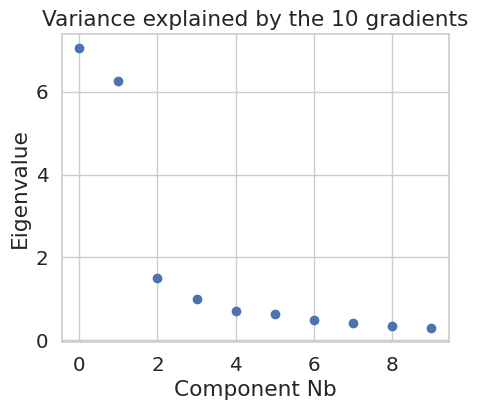

Total amount of variance explained by the 10 gradients (uncorrected sum lambdas): 18.71

G1: 37.66%
G2: 33.44%
G3: 8.02


In [128]:
# don't save these screenshots! (saves G1 and I actually want flipped -> next cells)
mean_fc_grad_fu2y = compute_mean_gradients(mean_fc_matrix_fu2y, display_output = True, data_reduction_algorithm = 'dm', kernel = 'cosine', save_screenshot = False, output_dir = resdir_fig, sample_modality = 'fc')

In [129]:
# I am creating a new variable with gradients that are flipped because I want G2 to go from sensory (-) to association (+) and I want to align individual level gradients to this
mean_fc_grad_flipped_fu2y = - mean_fc_grad_fu2y.gradients_

## Subject-level gradients (NOT ALIGNED)

In [130]:
# compute aligned gradients
compute_indvidual_gradients_fu2y = compute_indvidual_gradients_NOT_aligned(conn_matrices = fc_matrices_age2, ref_SA_axis = Margulies_gradients_schaefer400[0], data_reduction_algorithm = 'dm', kernel = 'cosine')

# store output of the gradient computation
array_SA_axis_fu2y = compute_indvidual_gradients_fu2y['array_SA_axis']
array_grad_other1_fu2y = compute_indvidual_gradients_fu2y['array_grad_other1']
array_grad_other2_fu2y = compute_indvidual_gradients_fu2y['array_grad_other2']
list_SA_axis_grad_num_fu2y = compute_indvidual_gradients_fu2y['list_SA_axis_grad_num']
list_SA_axis_corr_to_ref_fu2y = compute_indvidual_gradients_fu2y['list_SA_axis_corr_to_ref']
scaled_var_exp_SA_axis_fu2y = compute_indvidual_gradients_fu2y['scaled_var_exp_SA_axis']
scaled_var_exp_other1_fu2y = compute_indvidual_gradients_fu2y['scaled_var_exp_other1']
scaled_var_exp_other2_fu2y = compute_indvidual_gradients_fu2y['scaled_var_exp_other2']
diff_scaled_var_exp_SA_axis_other1_fu2y = compute_indvidual_gradients_fu2y['diff_scaled_var_exp_SA_axis_other1']


In [131]:
array_SA_axis_fu2y.shape

(1197, 400)

In [132]:
Counter(list_SA_axis_grad_num_fu2y)

Counter({1: 706, 2: 473, 3: 17, 4: 1})

/tmp/ipykernel_38588/797398177.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


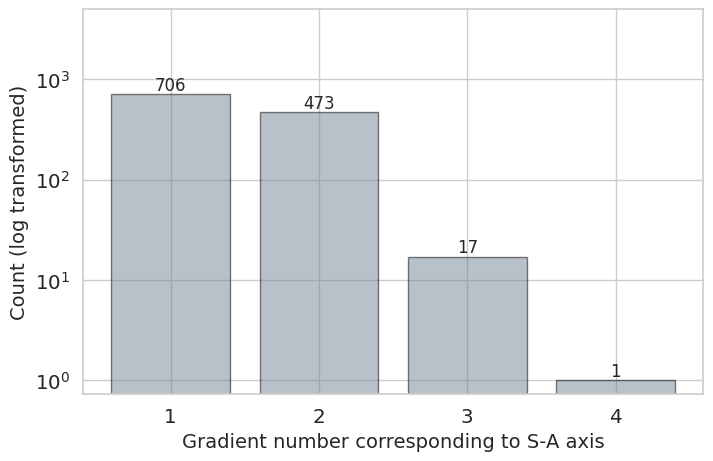

In [133]:
counts = Counter(list_SA_axis_grad_num_fu2y)

# Sort by key to keep the x-axis in order
keys = sorted(counts.keys())
values = [counts[k] for k in keys]

# Style setup (match your other figures)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create the bar plot
plt.figure(figsize=(8, 5))

bars = plt.bar(keys, values, color='xkcd:steel', alpha=0.5, edgecolor='black')

plt.xlabel('Gradient number corresponding to S-A axis', fontsize=14)
plt.ylabel('Count (log transformed)', fontsize=14)
#plt.title('Counts of Axis Gradient Numbers at Baseline', fontsize=16)
plt.xticks(keys)
plt.yscale('log')  # log scale
plt.ylim(0, 5000)

# Annotate counts on top of the bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of the bar
        value,                               # y position: top of the bar
        str(value),                          # text to display
        ha='center', va='bottom', fontsize=12
    )

plt.show()


In [134]:
# Compute the loading range for the S-A axis at individual level
SA_axis_fu2y_individual_range = np.max(array_SA_axis_fu2y, axis=1) - np.min(array_SA_axis_fu2y, axis=1)

In [135]:
print(f"Min correlation: r = {round(np.min(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"Max correlation: r = {round(np.max(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"Mean correlation: r = {round(np.mean(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"Median correlation: r = {round(np.median(list_SA_axis_corr_to_ref_fu2y),2)}")
print(f"STD correlation: r = {round(np.std(list_SA_axis_corr_to_ref_fu2y),10)}")
print(f"Mean individual range: r = {round(np.mean(SA_axis_fu2y_individual_range),2)}")

Min correlation: r = 0.37
Max correlation: r = 0.95
Mean correlation: r = 0.76
Median correlation: r = 0.77
STD correlation: r = 0.0925751975
Mean individual range: r = 15.29


In [136]:
data = list_SA_axis_corr_to_ref_fu2y
# Coefficient of variation
print("CV = std / mean. Scale-free measure of relative dispersion")
print(np.std(data, ddof=1) / np.mean(data))

# Interquartile range
print("\nIQR = Q3 - Q1. Middle 50% spread, robust to outliers")
print(np.percentile(data, 75) - np.percentile(data, 25))

# Median absolute deviation
print("\nMAD = median(|xi - median(x)|). Robust, outlier-resistant spread")
print(np.median(np.abs(data - np.median(data))))

# Normalized range
print("\nNR = (max - min) / mean. Simple but sensitive to outliers")
print((np.max(data) - np.min(data)) / np.mean(data))

# Gini coefficient
print("\nGini coefficient. 0 = perfect equality, 1 = maximal inequality")
sorted_data = np.sort(data)
n = len(sorted_data)
index = np.arange(1, n + 1)
print((2 * np.sum(index * sorted_data) / (n * np.sum(sorted_data))) - (n + 1) / n)

CV = std / mean. Scale-free measure of relative dispersion
0.12152744166042821

IQR = Q3 - Q1. Middle 50% spread, robust to outliers
0.1330172688579303

MAD = median(|xi - median(x)|). Robust, outlier-resistant spread
0.06660679129244551

NR = (max - min) / mean. Simple but sensitive to outliers
0.7537603310505622

Gini coefficient. 0 = perfect equality, 1 = maximal inequality
0.06886236872439655


In [137]:
print(f"Min scaled variance explained by S-A axis: {round(np.min(scaled_var_exp_SA_axis_fu2y),2)}")
print(f"Max scaled variance explained by S-A axis: {round(np.max(scaled_var_exp_SA_axis_fu2y),2)}")
print("")
print(f"Min difference variance explained by S-A axis and other gradient 1: {round(np.min(diff_scaled_var_exp_SA_axis_other1_fu2y),2)}")
print(f"Max difference variance explained by S-A axis and other gradient 1: {round(np.max(diff_scaled_var_exp_SA_axis_other1_fu2y),2)}")

Min scaled variance explained by S-A axis: 0.09
Max scaled variance explained by S-A axis: 58.36

Min difference variance explained by S-A axis and other gradient 1: -91.26
Max difference variance explained by S-A axis and other gradient 1: 55.68


#
#
#
#
# Compute gradients - Overall - Age Bin 3 (not fc/grad arrays for simplicity)

## Mean gradients

In [138]:
mean_fc_matrix_fu4y = np.sum(fc_matrices_age3, axis=0)/len(fc_matrices_age3)

In [139]:
mean_fc_matrix_fu4y.shape

(400, 400)

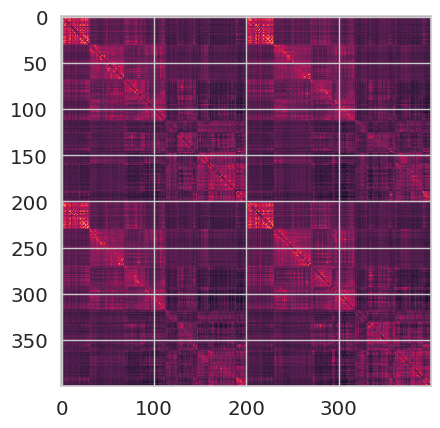

(400, 400)


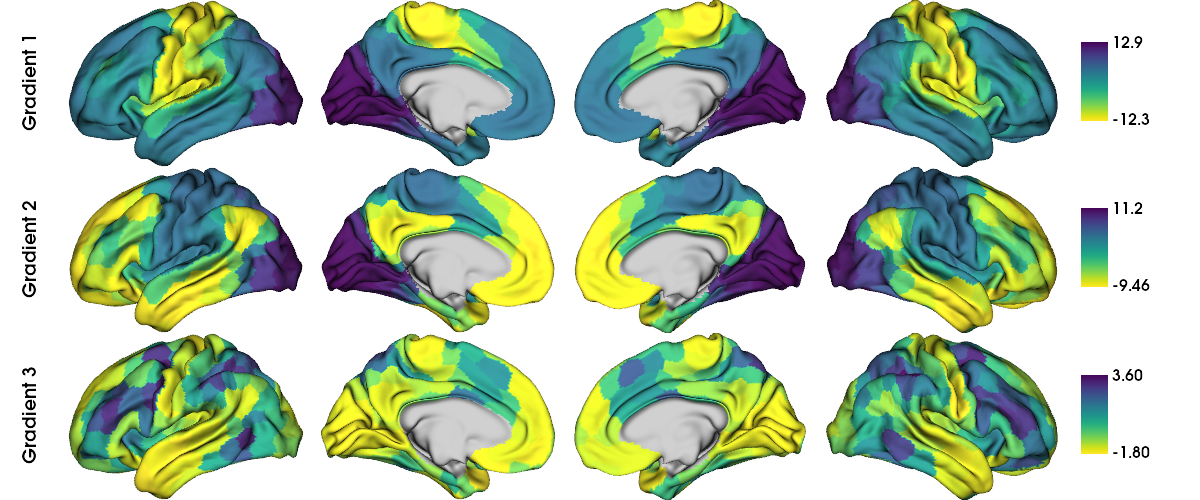

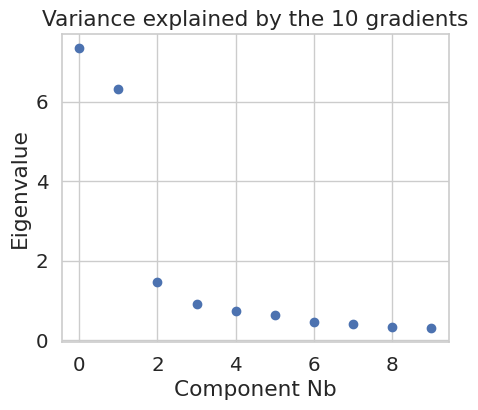

Total amount of variance explained by the 10 gradients (uncorrected sum lambdas): 18.98

G1: 38.68%
G2: 33.28%
G3: 7.80


In [140]:
# don't save these screenshots! (saves G1 and I actually want flipped -> next cells)
mean_fc_grad_fu4y = compute_mean_gradients(mean_fc_matrix_fu4y, display_output = True, data_reduction_algorithm = 'dm', kernel = 'cosine', save_screenshot = False, output_dir = resdir_fig, sample_modality = 'fc')

In [141]:
# I am creating a new variable with gradients that are flipped because I want G2 to go from sensory (-) to association (+) and I want to align individual level gradients to this
mean_fc_grad_flipped_fu4y = - mean_fc_grad_fu4y.gradients_

## Subject-level gradients (NOT ALIGNED)

In [142]:
# compute aligned gradients
compute_indvidual_gradients_fu4y = compute_indvidual_gradients_NOT_aligned(conn_matrices = fc_matrices_age3, ref_SA_axis = Margulies_gradients_schaefer400[0], data_reduction_algorithm = 'dm', kernel = 'cosine')

# store output of the gradient computation
array_SA_axis_fu4y = compute_indvidual_gradients_fu4y['array_SA_axis']
array_grad_other1_fu4y = compute_indvidual_gradients_fu4y['array_grad_other1']
array_grad_other2_fu4y = compute_indvidual_gradients_fu4y['array_grad_other2']
list_SA_axis_grad_num_fu4y = compute_indvidual_gradients_fu4y['list_SA_axis_grad_num']
list_SA_axis_corr_to_ref_fu4y = compute_indvidual_gradients_fu4y['list_SA_axis_corr_to_ref']
scaled_var_exp_SA_axis_fu4y = compute_indvidual_gradients_fu4y['scaled_var_exp_SA_axis']
scaled_var_exp_other1_fu4y = compute_indvidual_gradients_fu4y['scaled_var_exp_other1']
scaled_var_exp_other2_fu4y = compute_indvidual_gradients_fu4y['scaled_var_exp_other2']
diff_scaled_var_exp_SA_axis_other1_fu4y = compute_indvidual_gradients_fu4y['diff_scaled_var_exp_SA_axis_other1']


In [143]:
array_SA_axis_fu4y.shape

(951, 400)

In [144]:
Counter(list_SA_axis_grad_num_fu4y)

Counter({1: 622, 2: 320, 3: 9})

/tmp/ipykernel_38588/4178445155.py:22: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  plt.ylim(0, 5000)


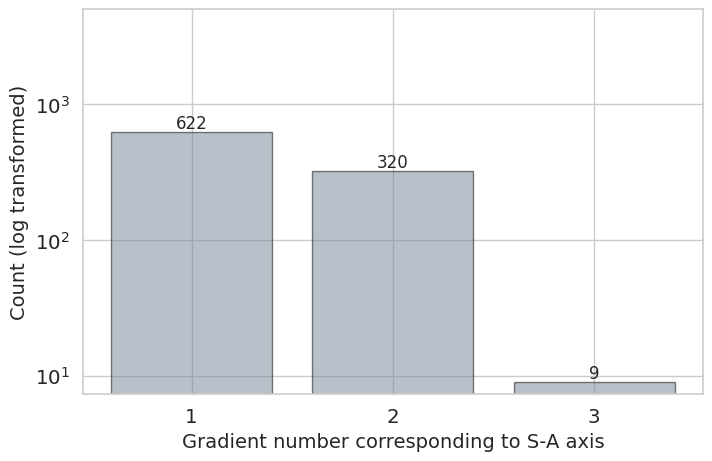

In [145]:
counts = Counter(list_SA_axis_grad_num_fu4y)

# Sort by key to keep the x-axis in order
keys = sorted(counts.keys())
values = [counts[k] for k in keys]

# Style setup (match your other figures)
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# Create the bar plot
plt.figure(figsize=(8, 5))

bars = plt.bar(keys, values, color='xkcd:steel', alpha=0.5, edgecolor='black')

plt.xlabel('Gradient number corresponding to S-A axis', fontsize=14)
plt.ylabel('Count (log transformed)', fontsize=14)
#plt.title('Counts of Axis Gradient Numbers at Baseline', fontsize=16)
plt.xticks(keys)
plt.yscale('log')  # log scale
plt.ylim(0, 5000)

# Annotate counts on top of the bars
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,  # x position: center of the bar
        value,                               # y position: top of the bar
        str(value),                          # text to display
        ha='center', va='bottom', fontsize=12
    )

plt.show()


In [146]:
# Compute the loading range for the S-A axis at individual level
SA_axis_fu4y_individual_range = np.max(array_SA_axis_fu4y, axis=1) - np.min(array_SA_axis_fu4y, axis=1)

In [147]:
print(f"Min correlation: r = {round(np.min(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"Max correlation: r = {round(np.max(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"Mean correlation: r = {round(np.mean(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"Median correlation: r = {round(np.median(list_SA_axis_corr_to_ref_fu4y),2)}")
print(f"STD correlation: r = {round(np.std(list_SA_axis_corr_to_ref_fu4y),10)}")
print(f"Mean individual range: r = {round(np.mean(SA_axis_fu4y_individual_range),2)}")

Min correlation: r = 0.51
Max correlation: r = 0.94
Mean correlation: r = 0.78
Median correlation: r = 0.79
STD correlation: r = 0.089267298
Mean individual range: r = 16.01


In [148]:
data = list_SA_axis_corr_to_ref_fu4y
# Coefficient of variation
print("CV = std / mean. Scale-free measure of relative dispersion")
print(np.std(data, ddof=1) / np.mean(data))

# Interquartile range
print("\nIQR = Q3 - Q1. Middle 50% spread, robust to outliers")
print(np.percentile(data, 75) - np.percentile(data, 25))

# Median absolute deviation
print("\nMAD = median(|xi - median(x)|). Robust, outlier-resistant spread")
print(np.median(np.abs(data - np.median(data))))

# Normalized range
print("\nNR = (max - min) / mean. Simple but sensitive to outliers")
print((np.max(data) - np.min(data)) / np.mean(data))

# Gini coefficient
print("\nGini coefficient. 0 = perfect equality, 1 = maximal inequality")
sorted_data = np.sort(data)
n = len(sorted_data)
index = np.arange(1, n + 1)
print((2 * np.sum(index * sorted_data) / (n * np.sum(sorted_data))) - (n + 1) / n)

CV = std / mean. Scale-free measure of relative dispersion
0.11403693863697371

IQR = Q3 - Q1. Middle 50% spread, robust to outliers
0.13472156075975472

MAD = median(|xi - median(x)|). Robust, outlier-resistant spread
0.06780436127725786

NR = (max - min) / mean. Simple but sensitive to outliers
0.5549749876416071

Gini coefficient. 0 = perfect equality, 1 = maximal inequality
0.0646244992517746


In [149]:
print(f"Min scaled variance explained by S-A axis: {round(np.min(scaled_var_exp_SA_axis_fu4y),2)}")
print(f"Max scaled variance explained by S-A axis: {round(np.max(scaled_var_exp_SA_axis_fu4y),2)}")
print("")
print(f"Min difference variance explained by S-A axis and other gradient 1: {round(np.min(diff_scaled_var_exp_SA_axis_other1_fu4y),2)}")
print(f"Max difference variance explained by S-A axis and other gradient 1: {round(np.max(diff_scaled_var_exp_SA_axis_other1_fu4y),2)}")

Min scaled variance explained by S-A axis: 0.43
Max scaled variance explained by S-A axis: 56.16

Min difference variance explained by S-A axis and other gradient 1: -97.87
Max difference variance explained by S-A axis and other gradient 1: 50.27


#
#
#
# Plotting for Figure

## Defining min and max gradient loadings across all (for common colorbar) and computing mean gradient range by timpoint

In [150]:
all_mean_grads = [mean_fc_grad.gradients_, mean_fc_grad_fu2y.gradients_, mean_fc_grad_fu4y.gradients_]

min_loading_across_all_G1 = 0
max_loading_across_all_G1 = 0

min_loading_across_all_G2 = 0
max_loading_across_all_G2 = 0

G1_mean_range = []
G2_mean_range = []

for grads_timepoint in all_mean_grads:

    ### G1

    # checking min and max
    if min(grads_timepoint[:, 0]) < min_loading_across_all_G1:
        min_loading_across_all_G1 = min(grads_timepoint[:, 0])
    if max(grads_timepoint[:, 0]) > max_loading_across_all_G1:
        max_loading_across_all_G1 = max(grads_timepoint[:, 0])

    # computing range
    G1_mean_range.append(max(grads_timepoint[:, 0]) - min(grads_timepoint[:, 0])) 

    
    ### G2

    # checking min and max
    if min(grads_timepoint[:, 1]) < min_loading_across_all_G2:
        min_loading_across_all_G2 = min(grads_timepoint[:, 1])

    if max(grads_timepoint[:, 1]) > max_loading_across_all_G2:
        max_loading_across_all_G2 = max(grads_timepoint[:, 1])

    # computing range
    G2_mean_range.append(max(grads_timepoint[:, 1]) - min(grads_timepoint[:, 1])) 


## Mean gradients

### baseline

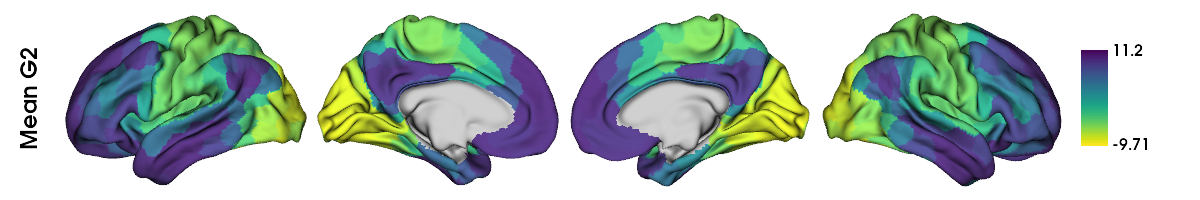

In [208]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad.gradients_[:, 1], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G2, max_loading_across_all_G2),
                        label_text=['Mean G2'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_baseline_mean_G2.svg')

display(plot)

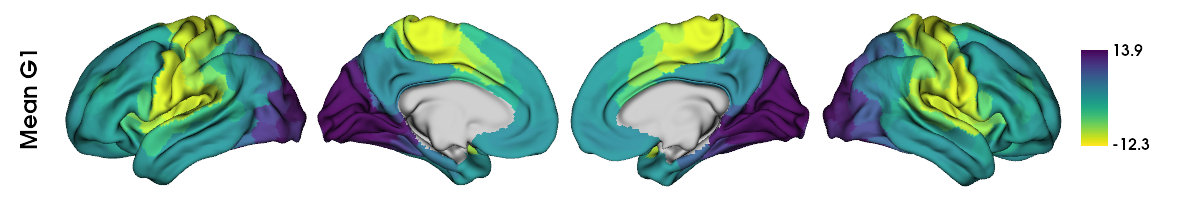

In [210]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad.gradients_[:, 0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Mean G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_baseline_mean_G1.svg')

display(plot)

### fu2y

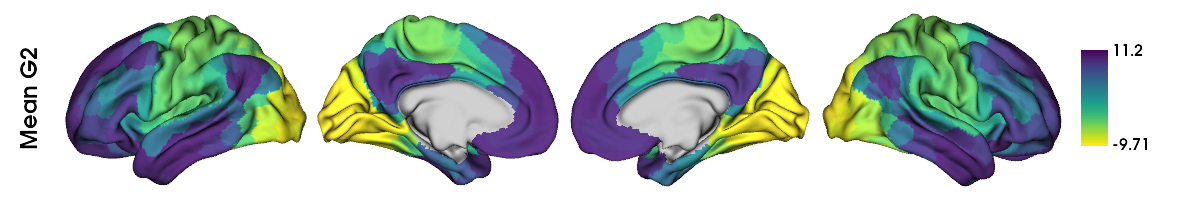

In [212]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = - map_to_labels(mean_fc_grad_fu2y.gradients_[:, 1], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G2, max_loading_across_all_G2),
                        label_text=['Mean G2'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu2y_mean_G2.svg')

display(plot)

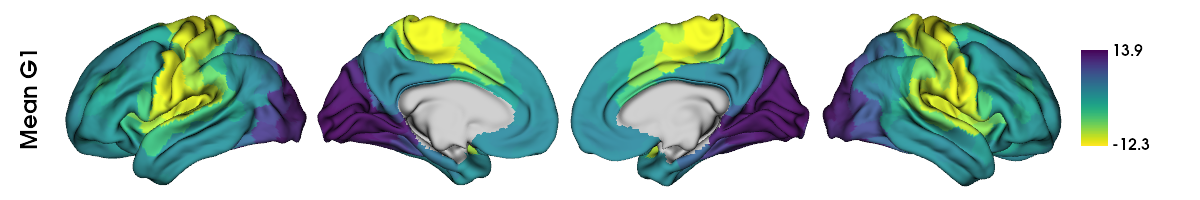

In [214]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad_fu2y.gradients_[:, 0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Mean G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu2y_mean_G1.svg')

display(plot)

### fu4y

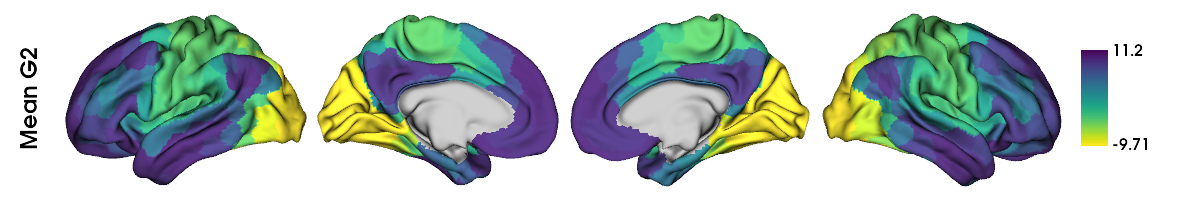

In [217]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(- mean_fc_grad_fu4y.gradients_[:, 1], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G2, max_loading_across_all_G2),
                        label_text=['Mean G2'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu4y_mean_G2.svg')

display(plot)

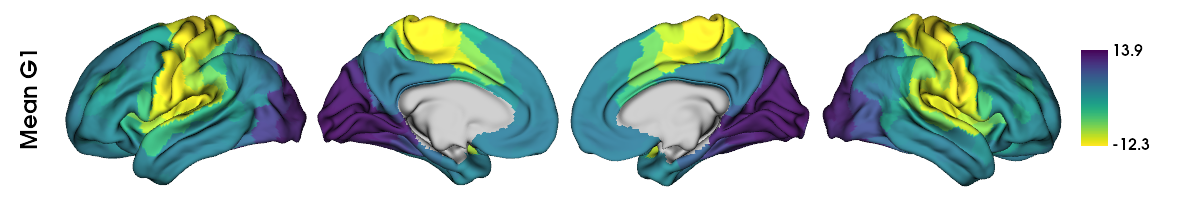

In [219]:
# defining labeling scheme and mask
labeling = load_parcellation('schaefer', scale=400, join=True)
surf_lh, surf_rh = load_conte69()
mask = labeling != 0

# map the gradient to the parcels
grad = map_to_labels(mean_fc_grad_fu4y.gradients_[:, 0], labeling, mask=mask, fill=np.nan)

plot = plot_hemispheres(surf_lh, 
                        surf_rh, 
                        array_name=grad, 
                        embed_nb = True, 
                        size=(1200, 200),
                        cmap='viridis_r', 
                        nan_color = (0.7, 0.7, 0.7, 1),
                        color_bar=True, 
                        color_range = (min_loading_across_all_G1, max_loading_across_all_G1),
                        label_text=['Mean G1'], 
                        zoom=1.55,
                        screenshot = False,
                        filename = resdir_fig+'plotted_hemispheres_fu4y_mean_G1.svg')

display(plot)

## Correlations between mean gradients

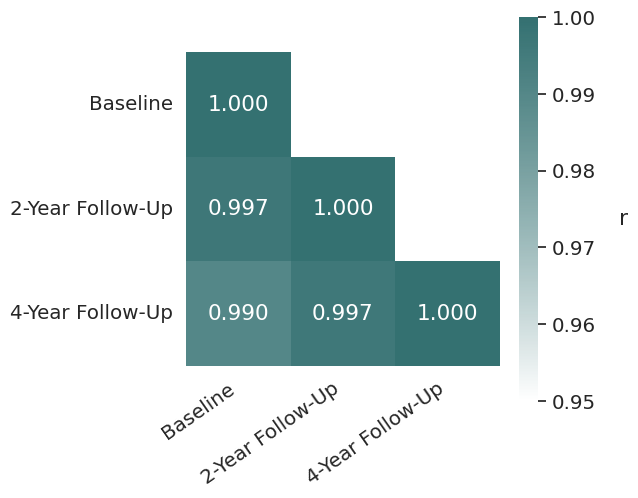

In [221]:
# --- Style setup ---
sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 1]
g_fu2y = - mean_fc_grad_fu2y.gradients_[:, 1]
g_fu4y = - mean_fc_grad_fu4y.gradients_[:, 1]

# --- Assemble into DataFrame ---
df_grad = pd.DataFrame({
    "Baseline": g_baseline,
    "2-Year Follow-Up": g_fu2y,
    "4-Year Follow-Up": g_fu4y
})

# --- Compute Spearman correlation matrix ---
corr_mat = df_grad.corr(method="spearman")

# --- Create single-hue colormap with alpha ---
base_color = mcolors.to_rgba("xkcd:dark teal", alpha=0.8)
cmap = mcolors.LinearSegmentedColormap.from_list(
    "indigo_alpha",
    [(1, 1, 1, 1), base_color]
)

# --- Plot heatmap ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))

mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)

# --- Apply mask by setting values to NaN ---
corr_plot = corr_mat.mask(mask)

hm = sns.heatmap(
    corr_plot,
    #mask=mask,
    ax=ax,
    cmap=cmap,
    vmin=0.95,
    vmax=1,
    square=True,
    annot=True,
    fmt=".3f",
    #linewidths=0.8,
    linewidths=0,          # <- no gridlines in masked area
    linecolor="black",
    cbar_kws={"label": "r"}
)


# Use mapped labels, only for observed categories
xtick_labels = df_grad.columns
ax.set_xticklabels(xtick_labels, rotation=35, ha="right")

# Rotate colorbar label
cbar = hm.collections[0].colorbar
cbar.set_label("r", rotation=0, labelpad=20)

# --- Improve aesthetics ---
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()

plt.savefig(resdir_fig+"corr_G2_heatmap.svg", dpi=300, bbox_inches="tight")


In [233]:
# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 1]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 1]
g_fu4y = mean_fc_grad_fu4y.gradients_[:, 1]

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu2y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-2y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-4y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_fu2y, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value: {spin_test_p}")

print(f"Spin permutation test p-value (2y-4y): {spin_test_p}")

permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-2y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-4y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value: 0.0
Spin permutation test p-value (2y-4y): 0.0


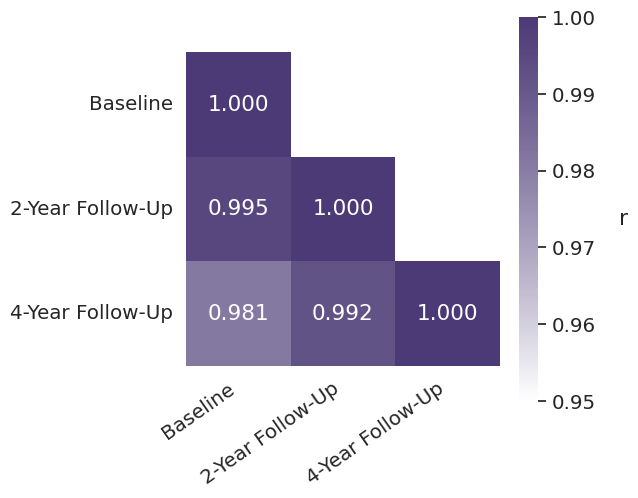

In [222]:
# --- Style setup ---
sns.set_theme(style="white", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 0]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 0]
g_fu4y = mean_fc_grad_fu4y.gradients_[:, 0]

# --- Assemble into DataFrame ---
df_grad = pd.DataFrame({
    "Baseline": g_baseline,
    "2-Year Follow-Up": g_fu2y,
    "4-Year Follow-Up": g_fu4y
})

# --- Compute Spearman correlation matrix ---
corr_mat = df_grad.corr(method="spearman")

# --- Create single-hue colormap with alpha ---
base_color = mcolors.to_rgba("xkcd:dark indigo", alpha=0.8)
cmap = mcolors.LinearSegmentedColormap.from_list(
    "indigo_alpha",
    [(1, 1, 1, 1), base_color]
)

# --- Plot heatmap ---
fig, ax = plt.subplots(figsize=(6.5, 5.5))

mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)

# --- Apply mask by setting values to NaN ---
corr_plot = corr_mat.mask(mask)

hm = sns.heatmap(
    corr_plot,
    ax=ax,
    cmap=cmap,
    vmin=0.95,
    vmax=1,
    square=True,
    annot=True,
    fmt=".3f",
    #linewidths=0.8,
    linewidths=0,          # <- no gridlines in masked area
    linecolor="black",
    cbar_kws={"label": "r"}
)


# Use mapped labels, only for observed categories
xtick_labels = df_grad.columns
ax.set_xticklabels(xtick_labels, rotation=35, ha="right")

# Rotate colorbar label
cbar = hm.collections[0].colorbar
cbar.set_label("r", rotation=0, labelpad=20)

# --- Improve aesthetics ---
ax.set_xlabel("")
ax.set_ylabel("")

plt.tight_layout()

plt.savefig(resdir_fig+"corr_G1_heatmap.svg", dpi=300, bbox_inches="tight")


In [234]:
# --- Extract gradient vectors ---
g_baseline = mean_fc_grad.gradients_[:, 0]
g_fu2y = mean_fc_grad_fu2y.gradients_[:, 0]
g_fu4y = mean_fc_grad_fu4y.gradients_[:, 0]

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu2y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-2y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_baseline, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (baseline-4y): {spin_test_p}")

spin_test_p, spin_test_d = spin_test(  
        g_fu2y, 
        g_fu4y,
        surface_name='fsa5', 
        parcellation_name='schaefer_400',
        type='spearman', 
        n_rot=1000, 
        null_dist=True
    )

print(f"Spin permutation test p-value (2y-4y): {spin_test_p}")

permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-2y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (baseline-4y): 0.0
permutation 100 of 1000
permutation 200 of 1000
permutation 300 of 1000
permutation 400 of 1000
permutation 500 of 1000
permutation 600 of 1000
permutation 700 of 1000
permutation 800 of 1000
permutation 900 of 1000
permutation 1000 of 1000
Spin permutation test p-value (2y-4y): 0.0


## Scree plot

In [159]:
sum_lambdas_baseline = np.sum(mean_fc_grad.lambdas_)
sum_lambdas_fu2y = np.sum(mean_fc_grad_fu2y.lambdas_)
sum_lambdas_fu4y = np.sum(mean_fc_grad_fu4y.lambdas_)


scaled_var_explained_mean_grad_baseline = mean_fc_grad.lambdas_ / sum_lambdas_baseline * 100
scaled_var_explained_mean_grad_fu2y = mean_fc_grad_fu2y.lambdas_ / sum_lambdas_fu2y * 100
scaled_var_explained_mean_grad_fu4y = mean_fc_grad_fu4y.lambdas_ / sum_lambdas_fu4y * 100

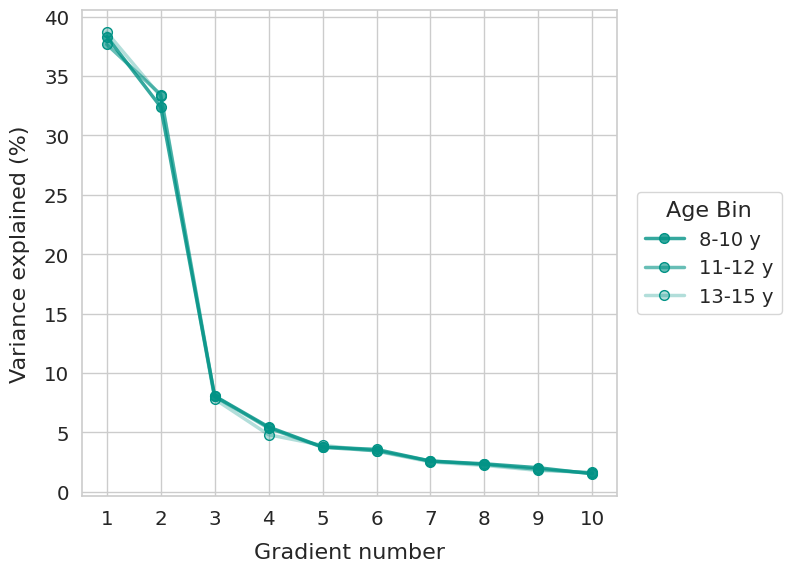

In [224]:
data = [
    scaled_var_explained_mean_grad_baseline,
    scaled_var_explained_mean_grad_fu2y,
    scaled_var_explained_mean_grad_fu4y
]


timepoints = ["8-10 y", "11-12 y", "13-15 y"]

alpha_map = {"8-10 y": 0.8, "11-12 y": 0.6, "13-15 y": 0.3}  # 0.8, 0.6, 0.3

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare data ---
x = np.arange(1, 11)  # Gradient numbers 1–10
#color_base = 'xkcd:golden yellow'
color_base = 'xkcd:teal'

# --- Create figure ---
fig, ax = plt.subplots(figsize=(7, 6))

# --- Draw lines and points ---
for i, tp in enumerate(timepoints):
    y = data[i]
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    
    ax.plot(
        x, y, 
        color=rgba, 
        linewidth=2.5, 
        marker='o', 
        markeredgecolor='xkcd:teal',  # prev xkcd:golden yellow
        markersize=7, 
        label=tp
    )

# --- Axis labels, ticks, and legend ---
ax.set_xticks(x)
ax.set_xticklabels(x)
ax.set_xlabel("Gradient number", fontsize=16, labelpad=10)
ax.set_ylabel("Variance explained (%)", fontsize=16, labelpad=10)

#ax.legend(
#    title="Timepoint", frameon=True, facecolor='white',
#    fontsize=14, title_fontsize=16, bbox_to_anchor=(0.95, 0.85)
#)

ax.legend(
    title="Age Bin",
    frameon=True,
    facecolor='white',
    fontsize=14,
    title_fontsize=16,
    loc='center left',
    bbox_to_anchor=(1.02, 0.5)  # (x, y) coordinates relative to the axes
)


plt.tight_layout()
plt.subplots_adjust(right=0.9)

# --- Save figure ---
plt.savefig(resdir_fig + "lineplot_var_explained_mean_grad.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()


In [161]:
scaled_var_explained_mean_grad_baseline[0:2]

array([38.32229481, 32.40098666])

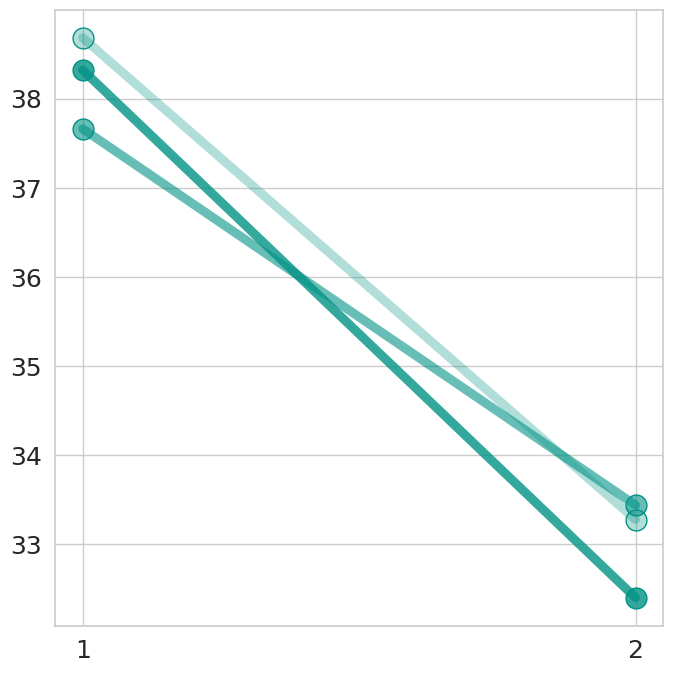

In [225]:
data = [
    scaled_var_explained_mean_grad_baseline[0:2],
    scaled_var_explained_mean_grad_fu2y[0:2],
    scaled_var_explained_mean_grad_fu4y[0:2]
]


timepoints = ["8-10 y", "11-12 y", "13-15 y"]

alpha_map = {"8-10 y": 0.8, "11-12 y": 0.6, "13-15 y": 0.3}  # 0.8, 0.6, 0.3

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare data ---
x = np.arange(1, 3)  # Gradient numbers 1–2
#color_base = 'xkcd:golden yellow'
color_base = 'xkcd:teal'

# --- Create figure ---
fig, ax = plt.subplots(figsize=(7, 7))

# --- Draw lines and points ---
for i, tp in enumerate(timepoints):
    y = data[i]
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    
    ax.plot(
        x, y, 
        color=rgba, 
        linewidth=6.5, 
        marker='o', 
        markeredgecolor='xkcd:teal',  # prev xkcd:golden yellow
        markersize=15, 
        label=tp
    )

# --- Axis labels, ticks, and legend --
ax.tick_params(axis='both', labelsize=18)
ax.set_xticks(x)
ax.set_xticklabels(x, fontsize=18)
#ax.set_xlabel("Gradient number", fontsize=16, labelpad=10)
#ax.set_ylabel("Variance explained (%)", fontsize=16, labelpad=10)

#ax.legend(
#    title="Timepoint", frameon=True, facecolor='white',
#    fontsize=14, title_fontsize=16, bbox_to_anchor=(0.95, 0.85)
#)

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "lineplot_var_explained_mean_grad_G1G2_zoom.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()


## Individual level distance to flip
-> i.e., difference between variance explained by S-A axis vs other gradient

Measure quantifying "how far" from gradient flip (interpretation assuming it's a continuous progression)

Positive value: flip has occured

Negative value: flip has not yet occured

/tmp/ipykernel_38588/4019689096.py:49: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='upper right', frameon=False)


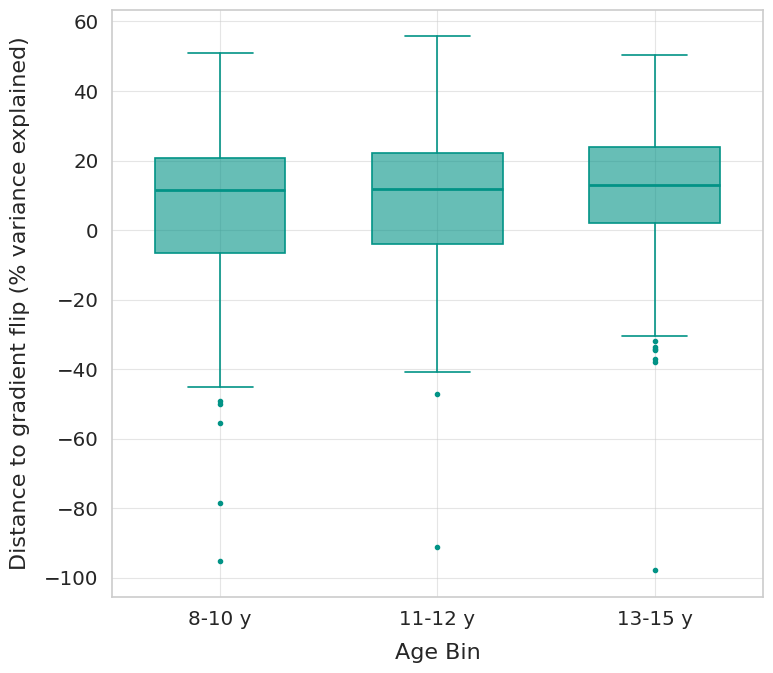

In [226]:
# --- Data setup ---

data = [
    diff_scaled_var_exp_SA_axis_other1_baseline,
    diff_scaled_var_exp_SA_axis_other1_fu2y,
    diff_scaled_var_exp_SA_axis_other1_fu4y
]


timepoints = ["8-10 y", "11-12 y", "13-15 y"]

alpha_map = {"8-10 y": 0.6, "11-12 y": 0.6, "13-15 y": 0.6}  # 0.8, 0.6, 0.3

color_base = 'xkcd:teal'



# --- Style setup (consistent with other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axis ---
fig, ax = plt.subplots(figsize=(8, 7))

# --- Draw boxplots ---
for i, tp in enumerate(timepoints):
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    ax.boxplot(
        data[i],
        positions=[i],
        widths=0.6,
        patch_artist=True,
        boxprops=dict(facecolor=rgba, color=color_base, linewidth=1.2),
        medianprops=dict(color=color_base, linewidth=2),
        whiskerprops=dict(color=color_base, linewidth=1.2),
        capprops=dict(color=color_base, linewidth=1.2),
        flierprops=dict(marker='o', markersize=3, alpha=1,
                        markerfacecolor=color_base, markeredgecolor='xkcd:teal')  # prev xkcd:golden yellow
    )


# --- Formatting ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Age Bin", fontsize=16, labelpad=10)
ax.set_ylabel("Distance to gradient flip (% variance explained)", fontsize=16, labelpad=10)
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)
ax.legend(loc='upper right', frameon=False)

#sns.despine()

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "boxplot_dist_to_flip.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


## S-A axis range

In [167]:
print(G1_mean_range)
print(G2_mean_range)

[24.474115888217774, 24.66675359983994, 25.149141196293904]
[17.908930717433506, 19.624023415346322, 20.665305257683134]


In [168]:
### Detecting outliers -> across timepoints

individual_range_all_timpoints = np.concatenate((SA_axis_baseline_individual_range, SA_axis_fu2y_individual_range, SA_axis_fu4y_individual_range), axis=0)

# Compute quartiles
Q1 = np.percentile(individual_range_all_timpoints, 25)
Q3 = np.percentile(individual_range_all_timpoints, 75)
IQR = Q3 - Q1

# Compute cutoff bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1 = {Q1:.2f}, Q3 = {Q3:.2f}, IQR = {IQR:.2f}")
print("\nLower and upper bounds are computed as Q1 - 1.5 * IQR and Q1 + 1.5 * IQR respectively")
print(f"Lower bound = {lower_bound:.2f}")
print(f"Upper bound = {upper_bound:.2f}")

# Identify outliers
outliers_baseline = SA_axis_baseline_individual_range[(SA_axis_baseline_individual_range < lower_bound) | (SA_axis_baseline_individual_range > upper_bound)]
outliers_fu2y = SA_axis_fu2y_individual_range[(SA_axis_fu2y_individual_range < lower_bound) | (SA_axis_fu2y_individual_range > upper_bound)]
outliers_fu4y = SA_axis_fu4y_individual_range[(SA_axis_fu4y_individual_range < lower_bound) | (SA_axis_fu4y_individual_range > upper_bound)]

print("")

print(f"Outliers baseline: {len(outliers_baseline)}:{outliers_baseline}")
print(f"Outliers fu2y: {len(outliers_fu2y)}: {outliers_fu2y}")
print(f"Outliers fu4y: {len(outliers_fu4y)}: {outliers_fu4y}")

print("")

print(f"Max outlier baseline: {np.round(max(SA_axis_baseline_individual_range), 2)}")
print(f"Max outlier fu2y: {np.round(max(SA_axis_fu2y_individual_range), 2)}")
print(f"Max outlier fu4y: {np.round(max(SA_axis_fu4y_individual_range), 2)}")


Q1 = 11.62, Q3 = 17.64, IQR = 6.03

Lower and upper bounds are computed as Q1 - 1.5 * IQR and Q1 + 1.5 * IQR respectively
Lower bound = 2.58
Upper bound = 26.68

Outliers baseline: 40:[ 32.5122698   28.77861266  28.28902642  27.38214255  26.74126284
  27.3751482   27.98697695  27.10852233  26.90547237  26.73654522
  29.50805498  28.87470609  27.25911118  50.12940988  27.14083296
  26.81363102  31.83049289  26.75961626  26.92163462  32.9878446
  27.68810996  29.55787315 385.44475413  27.15563366  27.77643731
  34.78741036  28.8533786   28.12336064  27.80782152  28.27411098
  28.50631286  27.43466737  28.1301927   28.56629402  33.21114849
  34.59658652  27.04153597  32.49738778  27.48965327  28.12272938]
Outliers fu2y: 10: [28.4190264  29.33927613 28.58704678 26.82741643 28.83946295 26.81922268
 27.07039053 38.24108704 30.86986716 29.50213628]
Outliers fu4y: 16: [29.1721418  27.14605347 34.92775474 27.28986419 27.38871998 33.871996
 27.92047742 27.39116048 29.71260862 29.26893353 28.6955

## R coef

In [173]:
### Computing r coef for correlation of mean G2 to adult S-A axis

G2_mean_rcoef = []
G2_mean_rcoef.append(stats.spearmanr(mean_fc_grad.gradients_[:,1], Margulies_gradients_schaefer400[0])[0])
G2_mean_rcoef.append(stats.spearmanr(- mean_fc_grad_fu2y.gradients_[:,1], Margulies_gradients_schaefer400[0])[0])
G2_mean_rcoef.append(stats.spearmanr(- mean_fc_grad_fu4y.gradients_[:,1], Margulies_gradients_schaefer400[0])[0])

In [174]:
G2_mean_rcoef

[0.8990971818573865, 0.884912155700973, 0.8724378902368138]

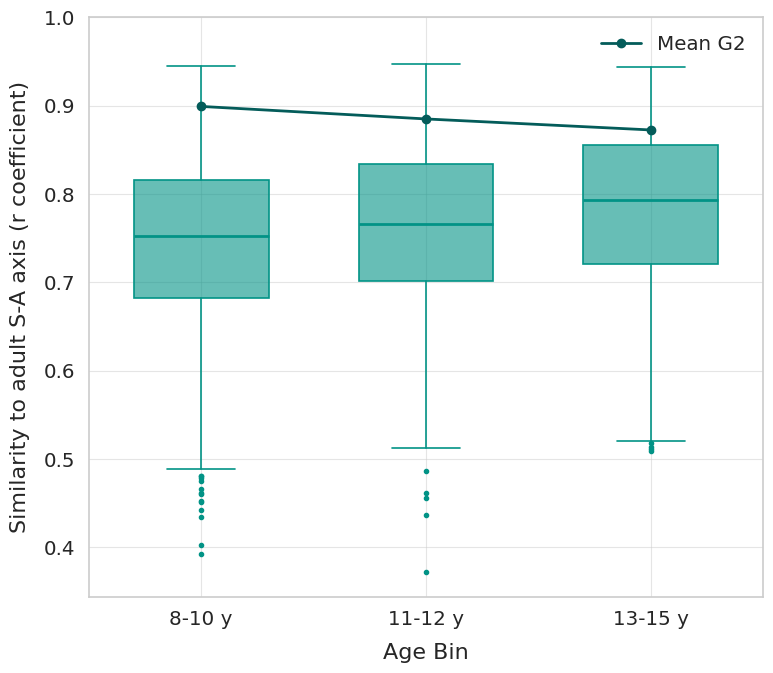

In [227]:
# --- Data setup ---

data = [
    list_SA_axis_corr_to_ref_baseline,
    list_SA_axis_corr_to_ref_fu2y,
    list_SA_axis_corr_to_ref_fu4y
]


timepoints = ["8-10 y", "11-12 y", "13-15 y"]

alpha_map = {"8-10 y": 0.6, "11-12 y": 0.6, "13-15 y": 0.6}  # 0.8, 0.6, 0.3

color_base = 'xkcd:teal'

# --- Style setup (consistent with other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2
plt.rcParams["boxplot.medianprops.linewidth"] = 2

# --- Create figure and axis ---
fig, ax = plt.subplots(figsize=(8, 7))

# --- Draw boxplots ---
for i, tp in enumerate(timepoints):
    rgba = mcolors.to_rgba(color_base, alpha=alpha_map[tp])
    ax.boxplot(
        data[i],
        positions=[i],
        widths=0.6,
        patch_artist=True,
        boxprops=dict(facecolor=rgba, color=color_base, linewidth=1.2),
        medianprops=dict(color=color_base, linewidth=2),
        whiskerprops=dict(color=color_base, linewidth=1.2),
        capprops=dict(color=color_base, linewidth=1.2),
        flierprops=dict(marker='o', markersize=3, alpha=1,
                        markerfacecolor=color_base, markeredgecolor='xkcd:teal')
    )

# --- (Optional) Overlay mean line across timepoints ---
ax.plot(np.arange(len(timepoints)), G2_mean_rcoef, marker='o', color='xkcd:dark turquoise', linewidth=2, label='Mean G2')

ax.set_ylim(top=1)

# --- Formatting ---
ax.set_xticks(np.arange(len(timepoints)))
ax.set_xticklabels(timepoints)
ax.set_xlabel("Age Bin", fontsize=16, labelpad=10)
ax.set_ylabel("Similarity to adult S-A axis (r coefficient)", fontsize=16, labelpad=10)
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)
ax.legend(loc='upper right', frameon=False)

#sns.despine()

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "boxplot_rcoef.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


In [177]:
print("Baseline")
print(f"Min rcoef: {np.min(list_SA_axis_corr_to_ref_baseline):.2f}")
print(f"Max rcoef: {np.max(list_SA_axis_corr_to_ref_baseline):.2f}")
print(f"Mean rcoef: {np.mean(list_SA_axis_corr_to_ref_baseline):.2f}, sd: {np.std(list_SA_axis_corr_to_ref_baseline):.2f}")
print(f"Median rcoef: {np.median(list_SA_axis_corr_to_ref_baseline):.2f}")

print("\n2y")
print(f"Min rcoef: {np.min(list_SA_axis_corr_to_ref_fu2y):.2f}")
print(f"Max rcoef: {np.max(list_SA_axis_corr_to_ref_fu2y):.2f}")
print(f"Mean rcoef: {np.mean(list_SA_axis_corr_to_ref_fu2y):.2f}, sd: {np.std(list_SA_axis_corr_to_ref_fu2y):.2f}")
print(f"Median rcoef: {np.median(list_SA_axis_corr_to_ref_fu2y):.2f}")

print("\n4y")
print(f"Min rcoef: {np.min(list_SA_axis_corr_to_ref_fu4y):.2f}")
print(f"Max rcoef: {np.max(list_SA_axis_corr_to_ref_fu4y):.2f}")
print(f"Mean rcoef: {np.mean(list_SA_axis_corr_to_ref_fu4y):.2f}, sd: {np.std(list_SA_axis_corr_to_ref_fu4y):.2f}")
print(f"Median rcoef: {np.median(list_SA_axis_corr_to_ref_fu4y):.2f}")

Baseline
Min rcoef: 0.39
Max rcoef: 0.94
Mean rcoef: 0.75, sd: 0.09
Median rcoef: 0.75

2y
Min rcoef: 0.37
Max rcoef: 0.95
Mean rcoef: 0.76, sd: 0.09
Median rcoef: 0.77

4y
Min rcoef: 0.51
Max rcoef: 0.94
Mean rcoef: 0.78, sd: 0.09
Median rcoef: 0.79


## Gradient flip

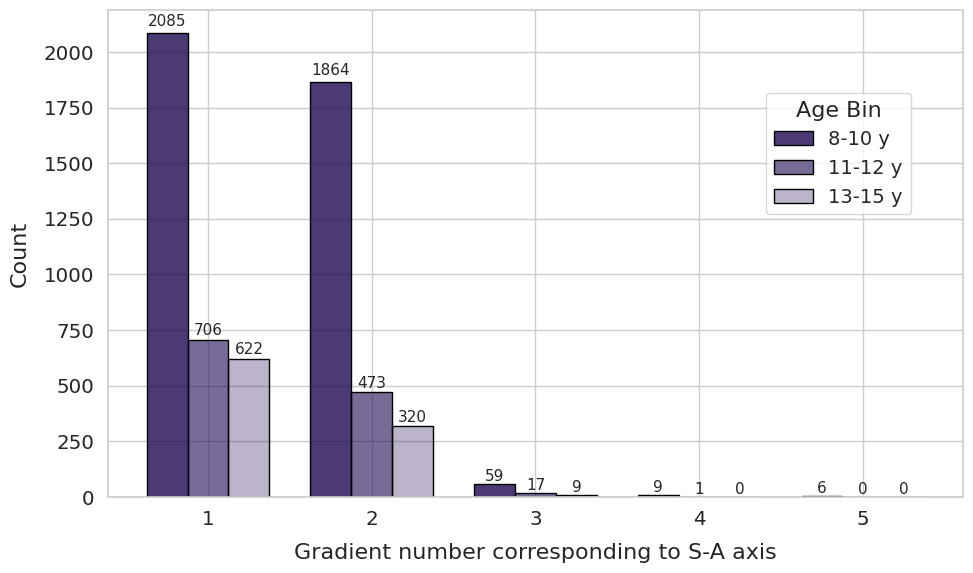

In [228]:
data_counts = [
    Counter(list_SA_axis_grad_num_baseline),
    Counter(list_SA_axis_grad_num_fu2y),
    Counter(list_SA_axis_grad_num_fu4y)
]



timepoints = ["8-10 y", "11-12 y", "13-15 y"]

alpha_map = {"8-10 y": 0.8, "11-12 y": 0.6, "13-15 y": 0.3}  # 0.8, 0.6, 0.3


# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare bar plot data ---
keys = sorted(set().union(*[c.keys() for c in data_counts]))
values_matrix = [[c.get(k, 0) for k in keys] for c in data_counts]
x = np.arange(len(keys))
width = 0.25

# --- Create single continuous axis figure ---
fig, ax = plt.subplots(figsize=(10, 6))

# --- Draw bars on single axis ---
for i, tp in enumerate(timepoints):
    values = values_matrix[i]
    rgba = mcolors.to_rgba('xkcd:dark indigo', alpha=alpha_map[tp])
    bar_positions = x + i * width - width

    bars = ax.bar(
        bar_positions, values, width=width,
        color=rgba, edgecolor='black', label=tp
    )

    # Annotate counts on bars
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, val*1.01, str(val),
                ha='center', va='bottom', fontsize=11)

# --- Axis labels and legend ---
ax.set_xticks(x)
ax.set_xticklabels(keys)
ax.set_xlabel("Gradient number corresponding to S-A axis", fontsize=16, labelpad=10)
ax.set_ylabel("Count", fontsize=16, labelpad=10)

ax.legend(title="Age Bin", frameon=True, facecolor='white', fontsize=14, title_fontsize=16, bbox_to_anchor=(0.95, 0.85))

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig+"barplot_gradient_counts.svg", format="svg", bbox_inches="tight", dpi=300)

plt.show()


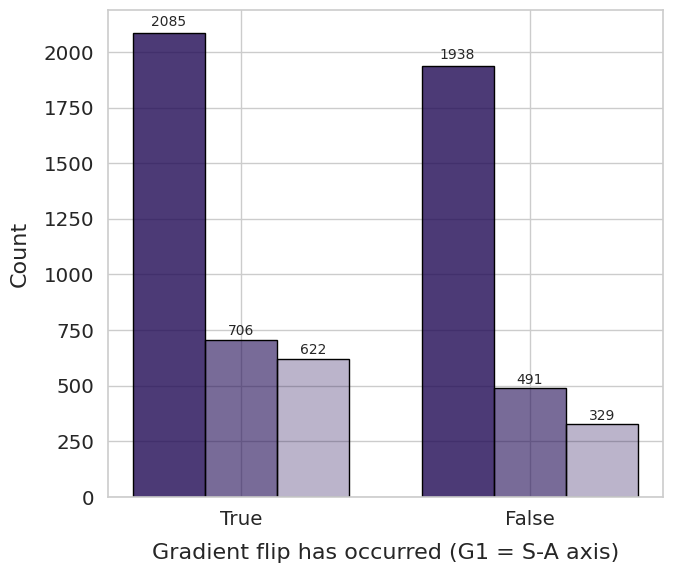

In [229]:
import matplotlib.colors as mcolors


# creating new lists of just 0s and 1s for if gradient flip has occurred or not: 1 True; 0 False
grad_flip_baseline = [True if x == 1 else False for x in list_SA_axis_grad_num_baseline]
grad_flip_fu2y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu2y]
grad_flip_fu4y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu4y]


# --- Count occurrences ---
data_counts = [
    Counter(grad_flip_baseline),
    Counter(grad_flip_fu2y),
    Counter(grad_flip_fu4y)
]

timepoints = ["8-10 y", "11-12 y", "13-15 y"]

alpha_map = {"8-10 y": 0.8, "11-12 y": 0.6, "13-15 y": 0.3}  # 0.8, 0.6, 0.3

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Prepare bar plot data ---
keys = sorted(set().union(*[c.keys() for c in data_counts]), reverse=True)
values_matrix = [[c.get(k, 0) for k in keys] for c in data_counts]
x = np.arange(len(keys))
width = 0.25

# --- Create single figure/axis ---
fig, ax = plt.subplots(figsize=(7, 6))

# --- Draw bars ---
for i, tp in enumerate(timepoints):
    values = values_matrix[i]
    rgba = mcolors.to_rgba('xkcd:dark indigo', alpha=alpha_map[tp])
    bar_positions = x + i * width - width

    bars = ax.bar(
        bar_positions, values, width=width,
        color=rgba, edgecolor='black', label=tp
    )

    # Annotate counts
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, val * 1.01, str(val),
                ha='center', va='bottom', fontsize=10)

# --- Axis formatting ---
ax.set_xticks(x)
ax.set_xticklabels(keys)
ax.set_xlabel("Gradient flip has occurred (G1 = S-A axis)", fontsize=16, labelpad=10)
ax.set_ylabel("Count", fontsize=16, labelpad=10)
#ax.legend(title="Timepoint", frameon=True, facecolor='white',fontsize=14, title_fontsize=16, bbox_to_anchor=(1.5, 0.85))

#sns.despine()
plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "barplot_gradflip_counts.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()


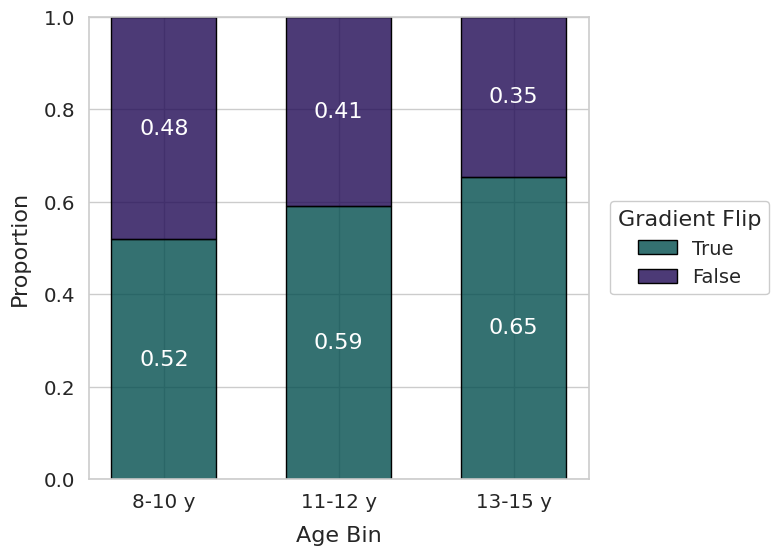

In [231]:
import matplotlib.colors as mcolors
from collections import Counter
from matplotlib.patches import Patch

# creating new lists of just True/False for if gradient flip has occurred or not
grad_flip_baseline = [True if x == 1 else False for x in list_SA_axis_grad_num_baseline]
grad_flip_fu2y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu2y]
grad_flip_fu4y = [True if x == 1 else False for x in list_SA_axis_grad_num_fu4y]

# --- Count occurrences ---
data_counts = [
    Counter(grad_flip_baseline),
    Counter(grad_flip_fu2y),
    Counter(grad_flip_fu4y)
]


timepoints = ["8-10 y", "11-12 y", "13-15 y"]

alpha_map = {"8-10 y": 0.8, "11-12 y": 0.8, "13-15 y": 0.8}  # 0.8, 0.6, 0.3

# --- Convert counts to proportions ---
data_props = []
for c in data_counts:
    total = sum(c.values())
    data_props.append({
        True: c.get(True, 0) / total,
        False: c.get(False, 0) / total
    })

# --- Style setup ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Create single figure/axis ---
fig, ax = plt.subplots(figsize=(8, 6))

x = np.arange(len(timepoints))
bar_width = 0.6

# --- Draw stacked bars ---
for i, tp in enumerate(timepoints):

    rgba_f = mcolors.to_rgba("xkcd:dark indigo", alpha=alpha_map[tp])  # False
    rgba_t = mcolors.to_rgba("xkcd:dark teal", alpha=alpha_map[tp])    # True

    false_prop = data_props[i][False]
    true_prop = data_props[i][True]

    # Bottom = True
    ax.bar(
        x[i],
        true_prop,
        width=bar_width,
        color=rgba_t,
        edgecolor="black"
    )

    # Top = False (stacked)
    ax.bar(
        x[i],
        false_prop,
        bottom=true_prop,
        width=bar_width,
        color=rgba_f,
        edgecolor="black"
    )

    # --- Proportion annotations (now correctly matched) ---
    ax.text(x[i], true_prop / 2, f"{true_prop:.2f}",
            ha="center", va="center", fontsize=16, color="white")

    ax.text(x[i], true_prop + false_prop / 2, f"{false_prop:.2f}",
            ha="center", va="center", fontsize=16, color="white")

# --- Axis formatting ---
ax.set_xticks(x)
ax.set_xticklabels(timepoints)
ax.set_xlabel("Age Bin", fontsize=16, labelpad=10)
ax.set_ylabel("Proportion", fontsize=16, labelpad=10)
ax.set_ylim(0, 1)

# --- Legend for True / False ---
legend_elements = [
    Patch(facecolor=mcolors.to_rgba("xkcd:dark teal", 0.8), edgecolor="black", label="True"),
    Patch(facecolor=mcolors.to_rgba("xkcd:dark indigo", 0.8), edgecolor="black", label="False"),
]
#ax.legend(handles=legend_elements, title="Gradient Flip", frameon=False, loc="upper right")


ax.legend(
    handles=legend_elements,
    title="Gradient Flip",
    bbox_to_anchor=(1.38, 0.5),
    loc="center right",
    frameon=True,  # enable the frame
    facecolor='white',       # background color
    #edgecolor='grey',       # border color
    framealpha=1,          # opacity of the frame (1.0 = opaque)
    fontsize=14,
    title_fontsize=16
)

plt.subplots_adjust(right=0.75)  # <-- makes room for legend outside
#plt.tight_layout()

# --- Save figure ---
plt.savefig(
    resdir_fig + "barplot_gradflip_proportions_stacked.svg",
    format="svg",
    bbox_inches="tight",
    dpi=300
)

plt.show()


In [181]:
# computing the flip occurence ratio (occured over not occured -> True / False) by timepoint
# True = 1; False = 0

flip_occurence_ratio_baseline = Counter(grad_flip_baseline)[1] / Counter(grad_flip_baseline)[0]
flip_occurence_ratio_fu2y = Counter(grad_flip_fu2y)[1] / Counter(grad_flip_fu2y)[0]
flip_occurence_ratio_fu4y = Counter(grad_flip_fu4y)[1] / Counter(grad_flip_fu4y)[0]

print(f"Flip occurence ratio:")
print(f"Baseline: {round(flip_occurence_ratio_baseline, 2)}")
print(f"Fu2y: {round(flip_occurence_ratio_fu2y, 2)}")
print(f"Fu4y: {round(flip_occurence_ratio_fu4y, 2)}")

Flip occurence ratio:
Baseline: 1.08
Fu2y: 1.44
Fu4y: 1.89


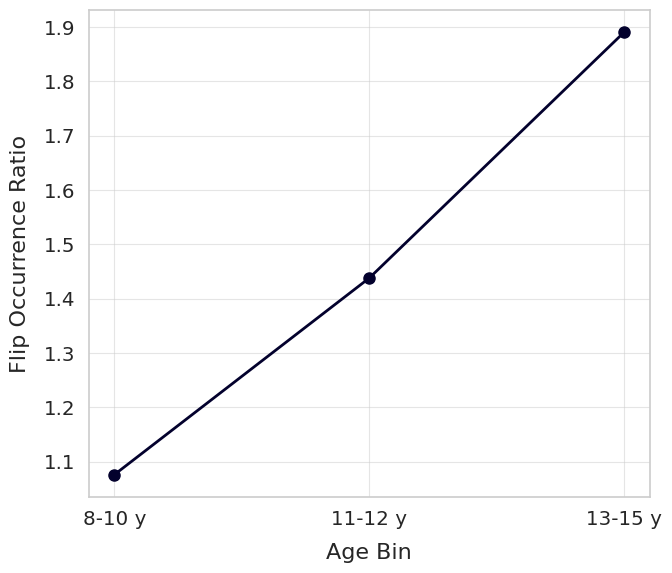

In [232]:

# --- Data setup ---

timepoints = ["8-10 y", "11-12 y", "13-15 y"]

data = [
    flip_occurence_ratio_baseline,
    flip_occurence_ratio_fu2y,
    flip_occurence_ratio_fu4y
]

# --- Style setup (match your other figures) ---
sns.set_theme(style="whitegrid", font="DejaVu Sans", font_scale=1.3)
plt.rcParams["axes.linewidth"] = 1.2

# --- Create figure and axis ---
fig, ax = plt.subplots(figsize=(7, 6))

# --- Plot line ---
x = np.arange(len(timepoints))
ax.plot(
    x, data,
    marker='o',
    markersize=8,
    color='xkcd:midnight',
    linewidth=2
)

# --- Axis formatting ---
ax.set_xticks(x)
ax.set_xticklabels(timepoints)
ax.set_xlabel("Age Bin", fontsize=16, labelpad=10)
ax.set_ylabel("Flip Occurrence Ratio", fontsize=16, labelpad=10)
ax.grid(True, linestyle='-', linewidth=0.8, alpha=0.5)
#sns.despine()

plt.tight_layout()

# --- Save figure ---
plt.savefig(resdir_fig + "lineplot_flip_occurrence_ratio.svg", format="svg", bbox_inches="tight", dpi=300)
plt.show()
